# Preference-Based Music Playlist Generation Under Duration and Genre Diversity Constraints
## Notebook 1 — AMBAR data preparation and composite preference score

This notebook turns the raw **AMBAR** files into a validated, per-user dataset that will be the input of the
Binary Integer Linear Programming (BILP) playlist model. **No optimization solver is implemented here.**

| Stage | Section |
|---|---|
| Configuration and setup | 0 |
| Stage 1 — Inspection and cleaning | 1–4 |
| Stage 2 — Preference components and composite score | 5–7 |
| Stage 3 — Statistical evaluation and visualizations | 8 |
| Stage 4 — Predicting missing ratings (user-based collaborative filtering) | 9 |
| Stage 5 — Candidate catalogue, genre indicators, scoring and export | 10–11 |
| Stage 6 — Final validation | 12 |
| Stage 7 — Link to the BILP model | 13 |
| Assumptions, limitations and biases | 14 |

**Output.** One CSV per user, containing **every** candidate song (rated and unrated) with only the columns
the optimization needs: `song_id`, `duration`, one 0/1 column per genre, and `preference_score`.

**Main design principle.** Every *contextual* component (popularity, country, genre, style, artist) is computed
**leave-one-out (LOO)**: the score of pair $(u,i)$ never uses the rating $r_{ui}$ itself. This
(1) prevents the user's own rating from being counted twice in the composite score,
(2) makes it possible to measure honestly how well each component predicts preferences, and
(3) makes the observed-track formula consistent with the formula for unseen tracks (Section 7.4).

**How to run (Windows, local virtual environment)**

```powershell
python -m venv .venv
.venv\Scripts\activate
pip install pandas numpy matplotlib pyarrow scipy jupyter
git clone https://github.com/davidcontrerasaguilar/AMBAR.git
mkdir data\raw
copy AMBAR\data\AMBAR\*.csv data\raw\
jupyter notebook
```

Place this notebook in the project root (or in a `notebooks/` subfolder); paths are resolved relative to it.
A full run takes a few minutes and about 3–4 GB of RAM with the default 100 exported users.

## 0. Configuration
All paths and tunable parameters are defined **only** in this cell.

In [1]:
from pathlib import Path

# --- Paths (relative to the project root) ---------------------------------
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent          # notebook stored in notebooks/
DATA_DIR      = PROJECT_ROOT / "data"
RAW_DIR       = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
USERS_OUT_DIR = PROCESSED_DIR / "users"
FIGURES_DIR   = PROCESSED_DIR / "figures"

RAW_FILES = {
    "users":   "users_info.csv",
    "tracks":  "tracks_info.csv",
    "artists": "artists_info.csv",
    "ratings": "ratings_info.csv",
}

# --- Rating semantics -------------------------------------------------------
RATING_MIN, RATING_MAX = 1, 5
POSITIVE_THRESHOLD = 4        # rating >= 4 is a positive (top two quintile levels); justified in Sec. 5.2

# --- Smoothing (pseudo-counts) ----------------------------------------------
KAPPA_TRACK      = 5.0        # track mean rating  -> shrunk toward global mean
LAMBDA_COUNTRY   = 10.0       # country-track mean -> shrunk toward track mean
ALPHA_COUNTRY    = 1.0        # alpha of the proportion formula (n_ci + a)/(N_c + 2a), evaluated as alternative
BETA_PROFILE     = 2.0        # user genre/style/artist profiles -> shrunk toward the user's mean
LAMBDA_ART_CTRY  = 20.0       # (user country, artist country) mean -> shrunk toward global mean

# --- Composite score weights -------------------------------------------------
W_INDIVIDUAL = 0.60           # weight of the observed individual rating (principal component)
WEIGHT_MODE  = "data_driven"  # "data_driven" (NNLS on training users) or "manual"
MANUAL_WEIGHTS = {            # used only if WEIGHT_MODE == "manual"; normalized to sum 1
    "individual_score": 0.60, "popularity_score": 0.05, "country_score": 0.05,
    "genre_similarity": 0.10, "style_similarity": 0.00, "artist_preference": 0.15,
    "artist_style_similarity": 0.05, "artist_country_score": 0.00,
}
HOLDOUT_FRACTION = 0.20       # share of each user's pairs hidden in the evaluation experiment
TRAIN_USER_FRACTION = 0.80    # user-level split for weight estimation
NNLS_MAX_ROWS = 1_000_000     # rows sampled from training users to fit NNLS

# --- Durations ---------------------------------------------------------------
MAX_REASONABLE_DURATION_S = 1800   # tracks longer than 30 min are kept but flagged as outliers

# --- Sampling for plots / sensitivity ----------------------------------------
RANDOM_SEED = 42
PLOT_SAMPLE_SIZE = 200_000
PROFILE_PLOT_USERS = 30
SENSITIVITY_N_USERS = 3000
TOP_N = 20

# --- Candidate catalogue (identical for every user file) ------------------------
MIN_LISTENERS = 20                 # a song needs >= 20 distinct listeners (about 14,000 songs)
EXCLUDE_DURATION_OUTLIERS = True   # drop songs longer than MAX_REASONABLE_DURATION_S from the catalogue

# --- Rating prediction: user-based collaborative filtering ---------------------
CF_NEIGHBORS = 50                  # k most similar users
CF_SIGNIFICANCE_GAMMA = 10         # similarity damped when users share fewer than gamma tracks
CF_SHRINK = 0.5                    # lambda_cf, pulls weakly supported predictions toward the user mean
CF_EVAL_USERS = 3000               # users in the hold-out evaluation of the predictor
CF_CHUNK_USERS = 500               # users processed at once (memory control)

# --- Export -------------------------------------------------------------------
EXPORT_USERS = None                # None -> random sample of N_EXPORT_USERS; or a list of user ids; or "all"
N_EXPORT_USERS = 100               # each file holds the whole catalogue (about 0.6 MB per user)
EXPORT_CHUNK_USERS = 100
CSV_FLOAT_DECIMALS = 6
VALIDATION_SAMPLE_FILES = 50       # user CSVs fully re-loaded and compared in Sec. 12
SAVE_FIGURES = True

print("Project root :", PROJECT_ROOT.resolve())
print("Raw data dir :", RAW_DIR.resolve())
print("Output dir   :", PROCESSED_DIR.resolve())

Project root : C:\Users\Ale\Downloads\Optimization methods\Proyecto_2
Raw data dir : C:\Users\Ale\Downloads\Optimization methods\Proyecto_2\data\raw
Output dir   : C:\Users\Ale\Downloads\Optimization methods\Proyecto_2\data\processed


In [2]:
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from scipy.optimize import nnls as _scipy_nnls
except ImportError:                       # fallback keeps the notebook runnable without SciPy
    _scipy_nnls = None

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
RNG = np.random.default_rng(RANDOM_SEED)
for d in (PROCESSED_DIR, USERS_OUT_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)

REPORT = {}            # everything that goes into the final processing report
T0 = time.perf_counter()
print("pandas", pd.__version__, "| numpy", np.__version__, "| SciPy NNLS available:", _scipy_nnls is not None)

pandas 3.0.5 | numpy 2.5.2 | SciPy NNLS available: True


### 0.1 Helper functions
Small, reusable functions: figure saving, multi-valued label parsing, NNLS, rank metrics.

In [3]:
def save_fig(fig, name):
    """Save a figure into FIGURES_DIR (if enabled) and show it."""
    fig.tight_layout()
    if SAVE_FIGURES:
        fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()


def explode_labels(df, id_col, label_col, sep="|"):
    """Parse a multi-valued 'a|b|c' column into one row per (id, label).

    Labels are stripped, empty labels dropped, repeated labels inside one string removed.
    Each label receives the weight 1/k (k = number of distinct labels of the item), so every
    item contributes a total weight of 1 regardless of how many labels it has.
    """
    tmp = df[[id_col, label_col]].copy()
    tmp["label"] = tmp[label_col].astype("string").str.split(sep)
    tmp = tmp.explode("label")
    tmp["label"] = tmp["label"].str.strip()
    tmp = tmp[tmp["label"].notna() & (tmp["label"] != "")]
    tmp = tmp.drop_duplicates([id_col, "label"])
    tmp["weight"] = 1.0 / tmp.groupby(id_col)["label"].transform("size")
    tmp["label"] = tmp["label"].astype("category")
    return tmp[[id_col, "label", "weight"]].reset_index(drop=True)


def nnls_fit(X, y):
    """Non-negative least squares: min ||X b - y||, b >= 0."""
    if _scipy_nnls is not None:
        b, _ = _scipy_nnls(X, y)
        return b
    # Fallback: iterative active-set via least squares with clipping
    active = np.ones(X.shape[1], bool)
    for _ in range(X.shape[1]):
        b = np.zeros(X.shape[1])
        b[active] = np.linalg.lstsq(X[:, active], y, rcond=None)[0]
        if (b >= 0).all():
            return b
        active &= b > 0
    return np.clip(b, 0, None)


def auc_from_scores(score, label):
    """ROC-AUC via the rank-sum (Mann-Whitney) formula; ties get average ranks."""
    r = pd.Series(score).rank(method="average").to_numpy()
    label = np.asarray(label, bool)
    n_pos, n_neg = label.sum(), (~label).sum()
    if n_pos == 0 or n_neg == 0:
        return np.nan
    return (r[label].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)


def within_user_spearman(frame, score_col, target_col="individual_score", user_col="user_id"):
    """Mean over users of the Spearman correlation between score and target (vectorized).
    Users whose target is constant (e.g., all ratings = 1) are skipped."""
    g = frame.groupby(user_col, sort=False)
    rx = g[score_col].rank(method="average")
    ry = g[target_col].rank(method="average")
    tmp = pd.DataFrame({user_col: frame[user_col].to_numpy(), "rx": rx.to_numpy(), "ry": ry.to_numpy()})
    gg = tmp.groupby(user_col, sort=False)
    tmp["dx"] = tmp["rx"] - gg["rx"].transform("mean")
    tmp["dy"] = tmp["ry"] - gg["ry"].transform("mean")
    s = tmp.assign(xy=tmp.dx * tmp.dy, xx=tmp.dx ** 2, yy=tmp.dy ** 2).groupby(user_col)[["xy", "xx", "yy"]].sum()
    valid = (s.xx > 0) & (s.yy > 0)
    rho = s.xy[valid] / np.sqrt(s.xx[valid] * s.yy[valid])
    return rho.mean(), int(valid.sum())


def human_size(n_bytes):
    for unit in ("B", "KB", "MB", "GB"):
        if n_bytes < 1024:
            return f"{n_bytes:,.1f} {unit}"
        n_bytes /= 1024
    return f"{n_bytes:,.1f} TB"

# STAGE 1 — Data inspection and cleaning
## 1. Load the raw files
Explicit dtypes keep memory low and detect malformed values early (a non-numeric identifier raises an error
instead of silently becoming `object`). Required columns are checked before any processing.

In [4]:
SCHEMAS = {
    "users":   {"user_id": "int64", "country": "string", "gender": "string", "continent": "string"},
    "tracks":  {"track_id": "int64", "artist_id": "int64", "duration": "float64",
                "styles": "string", "category_styles": "string"},
    "artists": {"artist_id": "int64", "gender": "string", "country": "string",
                "styles": "string", "category_styles": "string", "continent": "string"},
    "ratings": {"user_id": "int64", "track_id": "int64", "rating": "float64"},
}

def load_raw(name):
    path = RAW_DIR / RAW_FILES[name]
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {path}. Clone https://github.com/davidcontrerasaguilar/AMBAR.git and copy the four "
            f"CSV files from AMBAR/data/AMBAR/ into {RAW_DIR}.")
    try:
        df = pd.read_csv(path, dtype=SCHEMAS[name])
    except ValueError as exc:
        raise ValueError(f"{path.name}: a column could not be parsed with the expected dtype -> {exc}") from exc
    missing_cols = set(SCHEMAS[name]) - set(df.columns)
    if missing_cols:
        raise KeyError(f"{path.name} is missing required columns: {sorted(missing_cols)}")
    return df

raw = {name: load_raw(name) for name in RAW_FILES}
REPORT["original_dimensions"] = {k: list(v.shape) for k, v in raw.items()}
for k, v in raw.items():
    print(f"{k:8s} {v.shape[0]:>10,} rows x {v.shape[1]} cols | {human_size(v.memory_usage(deep=True).sum())}")

users        31,013 rows x 4 cols | 1.4 MB
tracks      443,921 rows x 5 cols | 25.2 MB
artists      30,667 rows x 6 cols | 2.8 MB
ratings   3,311,462 rows x 3 cols | 75.8 MB


## 2. Inspection before any merge
For each file: dimensions, dtypes, missing values, identifier uniqueness and duplicates. Three kinds of
duplicates are distinguished:

* **exact duplicates** — identical rows;
* **complementary duplicates** — same identifier, values agree wherever both are present (some are missing);
* **conflicting duplicates** — same identifier, at least one attribute with two different non-missing values.

In [5]:
ID_COLS = {"users": ["user_id"], "tracks": ["track_id"], "artists": ["artist_id"],
           "ratings": ["user_id", "track_id"]}

def inspect_frame(name, df):
    key = ID_COLS[name]
    dup_key = df.duplicated(key, keep=False)
    return {
        "rows": len(df), "cols": df.shape[1],
        "missing_cells": int(df.isna().sum().sum()),
        "exact_duplicate_rows": int(df.duplicated().sum()),
        "duplicated_key_rows (all copies)": int(dup_key.sum()),
        "distinct_keys": int(df.drop_duplicates(key).shape[0]),
        "key_is_unique": bool(not dup_key.any()),
    }

inspection = pd.DataFrame({k: inspect_frame(k, v) for k, v in raw.items()}).T
REPORT["inspection"] = inspection.astype(str).to_dict(orient="index")
display(inspection)

for k, v in raw.items():
    print(f"\n--- {k}: dtypes and missing values")
    display(pd.DataFrame({"dtype": v.dtypes.astype(str), "missing": v.isna().sum(),
                          "missing_%": (100 * v.isna().mean()).round(2)}).T)

,rows,cols,missing_cells,exact_duplicate_rows,duplicated_key_rows (all copies),distinct_keys,key_is_unique
users,31013,4,10168,1,16,31005,False
tracks,443921,5,0,0,0,443921,True
artists,30667,6,0,0,0,30667,True
ratings,3311462,3,0,1025122,2014091,2283607,False



--- users: dtypes and missing values


,user_id,country,gender,continent
dtype,int64,string,string,string
missing,0,5084,0,5084
missing_%,0.0,16.39,0.0,16.39



--- tracks: dtypes and missing values


,track_id,artist_id,duration,styles,category_styles
dtype,int64,int64,float64,string,string
missing,0,0,0,0,0
missing_%,0.0,0.0,0.0,0.0,0.0



--- artists: dtypes and missing values


,artist_id,gender,country,styles,category_styles,continent
dtype,int64,string,string,string,string,string
missing,0,0,0,0,0,0
missing_%,0.0,0.0,0.0,0.0,0.0,0.0



--- ratings: dtypes and missing values


,user_id,track_id,rating
dtype,int64,int64,float64
missing,0,0,0
missing_%,0.0,0.0,0.0


**Reading the inspection.** `track_id` and `artist_id` are unique. `users_info.csv` has a few repeated
`user_id`s, and `ratings_info.csv` contains a large number of repeated `(user_id, track_id)` pairs, most of them
exact copies. Both cases are resolved below without deleting valid information.

## 3. Cleaning each file
### 3.1 `users_info.csv` — consolidation of duplicated user identifiers
Decision rules (record-level, conservative):

| Case | Rule | Rationale |
|---|---|---|
| unique id | keep | — |
| exact duplicate | keep one copy | no information lost |
| complementary | merge field by field (first non-missing value) | values are consistent |
| conflicting | keep the user, set **all** demographic fields to missing, flag `conflict_excluded` | two different people may share the id; no value can be trusted |
| user in ratings but not in users_info | keep the user, demographics missing, flag `missing_metadata` | ratings are valid observations |

Ratings of users with excluded demographics are **kept**; only the country-based components fall back to
non-demographic estimates for them.

In [6]:
DEMO_COLS = ["country", "gender", "continent"]

def consolidate_users(users):
    users = users.copy()
    for c in DEMO_COLS:                                        # normalize blanks
        users[c] = users[c].str.strip().replace("", pd.NA)
    dup = users.duplicated("user_id", keep=False)
    single = users[~dup].assign(demographic_status="unique")
    multi = users[dup]

    n_distinct = multi.groupby("user_id")[DEMO_COLS].nunique(dropna=True)
    n_copies = multi.groupby("user_id").size()
    n_distinct_rows = multi.drop_duplicates().groupby("user_id").size()
    status = pd.Series("complementary_merged", index=n_distinct.index)
    status[n_distinct_rows == 1] = "exact_duplicate"
    status[(n_distinct > 1).any(axis=1)] = "conflict_excluded"

    merged = multi.groupby("user_id")[DEMO_COLS].first()        # first non-missing value per field
    merged.loc[status == "conflict_excluded", DEMO_COLS] = pd.NA
    merged = merged.assign(demographic_status=status).reset_index()

    detail = multi.merge(status.rename("status"), left_on="user_id", right_index=True)
    out = pd.concat([single, merged], ignore_index=True)
    assert out["user_id"].is_unique
    return out, detail, n_copies

users, users_dup_detail, _ = consolidate_users(raw["users"])
print("Duplicated user ids and the decision taken:")
display(users_dup_detail.sort_values(["status", "user_id"]))
print(users["demographic_status"].value_counts())

# country -> continent must be a function (one continent per country)
cc = users.dropna(subset=["country", "continent"]).groupby("country")["continent"].nunique()
assert (cc <= 1).all(), f"Countries mapped to several continents: {cc[cc > 1].index.tolist()}"

REPORT["users_cleaning"] = {
    "raw_rows": len(raw["users"]), "distinct_user_ids": int(users.shape[0]),
    **{k: int(v) for k, v in users["demographic_status"].value_counts().items()},
    "users_missing_country_after_cleaning": int(users["country"].isna().sum()),
}

Duplicated user ids and the decision taken:


,user_id,country,gender,continent,status
208,311457540,Brazil,M,South America,complementary_merged
31005,311457540,<NA>,M,<NA>,complementary_merged
7767,372293143,<NA>,M,<NA>,complementary_merged
24644,372293143,United Kingdom,M,Europe,complementary_merged
26656,38606714,Canada,F,North America,conflict_excluded
30993,38606714,Russian Federation,F,Europe,conflict_excluded
27359,39168978,<NA>,M,<NA>,conflict_excluded
31008,39168978,Cambodia,F,Asia,conflict_excluded
866,128783640,United States,M,North America,conflict_excluded
13193,128783640,Latvia,F,Europe,conflict_excluded


demographic_status
unique                  30997
conflict_excluded           5
complementary_merged        2
exact_duplicate             1
Name: count, dtype: int64


### 3.2 `tracks_info.csv` — durations and genre labels
* `duration` is in **seconds** (median ≈ 190 s). A value of **0 is not a real duration**: it means the duration
  is unknown (`duration_valid = False`). Duration is a constraint of the playlist model, so these tracks are
  **never candidates and never appear in the final dataset**. Their ratings are still kept as *listening
  history*, because they tell us about each user's taste and about similarities between users.
* Durations above `MAX_REASONABLE_DURATION_S` are kept and flagged (`duration_outlier`); they may be DJ mixes
  or full albums.
* `styles` (fine-grained) and `category_styles` (broad) are multi-valued strings separated by `|`.

In [7]:
tracks = raw["tracks"].copy()
assert tracks["track_id"].is_unique, "track_id must be unique"
assert not tracks["duration"].isna().any(), "duration contains NaN in the raw file"
assert (tracks["duration"] >= 0).all(), "negative durations found"
assert np.allclose(tracks["duration"], tracks["duration"].round()), "non-integer seconds found"

tracks["duration_valid"] = tracks["duration"] > 0
tracks["duration_s"] = tracks["duration"].where(tracks["duration_valid"]).astype("Int64")
tracks["duration_outlier"] = tracks["duration_s"].fillna(0) > MAX_REASONABLE_DURATION_S
for c in ("styles", "category_styles"):
    tracks[c] = tracks[c].str.strip()

track_cats = explode_labels(tracks, "track_id", "category_styles")
track_styles = explode_labels(tracks, "track_id", "styles")
assert track_cats["track_id"].nunique() == len(tracks), "every track must have at least one category"
assert not track_cats["label"].astype(str).str.contains(r"\|").any()   # no multi-genre string survived

REPORT["tracks_cleaning"] = {
    "tracks": len(tracks),
    "duration_zero_set_missing": int((~tracks["duration_valid"]).sum()),
    "duration_outliers_flagged": int(tracks["duration_outlier"].sum()),
    "distinct_track_categories": int(track_cats["label"].nunique()),
    "distinct_track_styles": int(track_styles["label"].nunique()),
}
print(REPORT["tracks_cleaning"])

# Diagnostic: the category 'Blue' (not 'Blues') -> which fine styles does it contain?
blue_ids = track_cats.loc[track_cats["label"] == "Blue", "track_id"]
print("\nStyles of tracks labelled 'Blue':")
print(track_styles[track_styles["track_id"].isin(blue_ids)]["label"].value_counts().head(5))

{'tracks': 443921, 'duration_zero_set_missing': 138787, 'duration_outliers_flagged': 176, 'distinct_track_categories': 16, 'distinct_track_styles': 282}

Styles of tracks labelled 'Blue':
label
rnb            2627
dance           141
trap             79
chill            56
alternative      27
Name: count, dtype: int64


**Note on the `Blue` category.** Tracks labelled `Blue` almost all have the fine style `rnb`, so `Blue` is
**not** a typo for `Blues`. It is kept as a separate category (it probably stands for R&B). Merging it with
`Blues` would introduce an error.

In [8]:
artists = raw["artists"].copy()
assert artists["artist_id"].is_unique, "artist_id must be unique"
for c in ("gender", "country", "continent", "styles", "category_styles"):
    artists[c] = artists[c].str.strip()
artists["gender_known"] = artists["gender"].ne("undefined")
artist_styles = explode_labels(artists, "artist_id", "styles")
assert artist_styles["artist_id"].nunique() == len(artists)

REPORT["artists_cleaning"] = {
    "artists": len(artists),
    "artist_gender_undefined": int((~artists["gender_known"]).sum()),
    "distinct_artist_styles": int(artist_styles["label"].nunique()),
}
print(REPORT["artists_cleaning"])

{'artists': 30667, 'artist_gender_undefined': 21253, 'distinct_artist_styles': 220}


### 3.4 `ratings_info.csv` — duplicated user–track pairs
* Ratings are validated to be integers in $[1,5]$.
* **Exact duplicates** (same user, track and rating) carry no extra information and are collapsed.
* **Conflicting duplicates** (same pair, different ratings) are kept as **one** pair whose rating is the
  **mean** of the conflicting values; `rating_conflict = True`. Almost all conflicts differ by one level
  (a quintile boundary), so the mean is the least arbitrary choice and no observation is dropped.

In [9]:
ratings_raw = raw["ratings"]
assert ratings_raw["rating"].between(RATING_MIN, RATING_MAX).all(), "ratings outside [1, 5]"
assert np.allclose(ratings_raw["rating"], ratings_raw["rating"].round()), "non-integer raw ratings"

n_exact = int(ratings_raw.duplicated().sum())
ratings = (ratings_raw.groupby(["user_id", "track_id"], sort=False)["rating"]
           .agg(rating="mean", rating_min="min", rating_max="max", n_records="size")
           .reset_index())
ratings["rating_conflict"] = ratings["rating_min"] != ratings["rating_max"]
conflict_gap = (ratings["rating_max"] - ratings["rating_min"])[ratings["rating_conflict"]]

REPORT["ratings_cleaning"] = {
    "raw_rows": len(ratings_raw),
    "exact_duplicate_rows_collapsed": n_exact,
    "unique_user_track_pairs": len(ratings),
    "conflicting_pairs_averaged": int(ratings["rating_conflict"].sum()),
    "conflict_gap_distribution": {str(k): int(v) for k, v in conflict_gap.value_counts().items()},
}
print(json.dumps(REPORT["ratings_cleaning"], indent=2))
ratings = ratings.drop(columns=["rating_min", "rating_max"])

{
  "raw_rows": 3311462,
  "exact_duplicate_rows_collapsed": 1025122,
  "unique_user_track_pairs": 2283607,
  "conflicting_pairs_averaged": 2733,
  "conflict_gap_distribution": {
    "1.0": 2715,
    "2.0": 16,
    "3.0": 2
  }
}


## 4. Foreign keys and merge
Relationships checked: `ratings.user_id → users`, `ratings.track_id → tracks`, `tracks.artist_id → artists`.
Merges use `validate="many_to_one"`, so pandas raises an error if a key that must be unique is not.

In [10]:
fk = {
    "rating_rows_user_not_in_users_info": int((~ratings["user_id"].isin(users["user_id"])).sum()),
    "users_in_ratings_not_in_users_info": int(len(set(ratings["user_id"]) - set(users["user_id"]))),
    "users_in_users_info_without_ratings": int(len(set(users["user_id"]) - set(ratings["user_id"]))),
    "rating_rows_track_not_in_tracks": int((~ratings["track_id"].isin(tracks["track_id"])).sum()),
    "tracks_artist_not_in_artists": int((~tracks["artist_id"].isin(artists["artist_id"])).sum()),
    "tracks_without_ratings": int((~tracks["track_id"].isin(ratings["track_id"])).sum()),
}
REPORT["foreign_keys"] = fk
print(json.dumps(fk, indent=2))
assert fk["rating_rows_track_not_in_tracks"] == 0, "ratings reference unknown tracks"
assert fk["tracks_artist_not_in_artists"] == 0, "tracks reference unknown artists"

# Users that rate but have no demographic record are added (not dropped).
missing_users = sorted(set(ratings["user_id"]) - set(users["user_id"]))
users = pd.concat([users, pd.DataFrame({"user_id": missing_users, "demographic_status": "missing_metadata"})],
                  ignore_index=True)
assert users["user_id"].is_unique

track_cols = ["track_id", "artist_id", "duration_s", "duration_valid", "duration_outlier", "styles", "category_styles"]
artist_cols = artists.rename(columns={"styles": "artist_styles", "category_styles": "artist_categories",
                                      "country": "artist_country", "gender": "artist_gender",
                                      "continent": "artist_continent"})
df = (ratings
      .merge(tracks[track_cols], on="track_id", how="left", validate="many_to_one")
      .merge(artist_cols[["artist_id", "artist_styles", "artist_categories", "artist_country",
                          "artist_gender", "artist_continent"]], on="artist_id", how="left", validate="many_to_one")
      .merge(users.rename(columns={"country": "user_country", "gender": "user_gender",
                                   "continent": "user_continent"}), on="user_id", how="left", validate="many_to_one")
      .rename(columns={"styles": "track_styles", "category_styles": "track_categories"}))

assert len(df) == len(ratings), "merge changed the number of user-track pairs"
assert not df.duplicated(["user_id", "track_id"]).any()
for c in ["user_country", "user_continent", "user_gender", "artist_country", "artist_styles"]:
    df[c] = df[c].astype("category")

merge_stats = {
    "pairs": len(df),
    "pairs_with_track_metadata_%": round(100 * df["artist_id"].notna().mean(), 3),
    "pairs_with_artist_metadata_%": round(100 * df["artist_styles"].notna().mean(), 3),
    "pairs_with_user_country_%": round(100 * df["user_country"].notna().mean(), 3),
    "pairs_with_valid_duration_%": round(100 * df["duration_valid"].mean(), 3),
}
REPORT["merge"] = merge_stats
print(json.dumps(merge_stats, indent=2))
print("\nMissing values after merge (%):")
display((100 * df.isna().mean()).round(2).to_frame("missing_%").T)
print(f"Memory of merged frame: {human_size(df.memory_usage(deep=True).sum())}")

{
  "rating_rows_user_not_in_users_info": 654,
  "users_in_ratings_not_in_users_info": 8,
  "users_in_users_info_without_ratings": 0,
  "rating_rows_track_not_in_tracks": 0,
  "tracks_artist_not_in_artists": 0,
  "tracks_without_ratings": 0
}
{
  "pairs": 2283607,
  "pairs_with_track_metadata_%": 100.0,
  "pairs_with_artist_metadata_%": 100.0,
  "pairs_with_user_country_%": 84.251,
  "pairs_with_valid_duration_%": 74.498
}

Missing values after merge (%):


,user_id,track_id,rating,n_records,rating_conflict,artist_id,duration_s,duration_valid,duration_outlier,track_styles,track_categories,artist_styles,artist_categories,artist_country,artist_gender,artist_continent,user_country,user_gender,user_continent,demographic_status
missing_%,0.0,0.0,0.0,0.0,0.0,0.0,25.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15.75,0.05,15.75,0.0


Memory of merged frame: 353.6 MB


**Effect of cleaning.** No rating row was deleted for lack of metadata. The only reduction comes from collapsing
duplicated user–track pairs. About a quarter of the pairs refer to tracks without a known duration. They are used
only as listening history (similarities, profiles). The final dataset and the user files contain only songs with a
positive duration (Section 10).

# STAGE 2 — Preference components
## 5. Notation and design
| Symbol | Meaning |
|---|---|
| $r_{ui}\in[1,5]$ | AMBAR rating (implicit, from playcount quintiles) |
| $I_{ui}=(r_{ui}-1)/4$ | normalized individual preference |
| $y_{ui}=\mathbb 1[r_{ui}\ge \tau]$ | positive indicator, $\tau$ = `POSITIVE_THRESHOLD` |
| $\mu$ | global mean of $I$ |
| $\mu_u$ | mean of $I$ over the history of user $u$ (constant within the user) |
| $c(u)$, $a(i)$ | country of user $u$, artist of track $i$ |

All contextual components are *shrinkage (Bayesian-average) estimators*:
$$\hat\theta=\frac{\sum \text{observed values} + \lambda\,\theta_0}{n+\lambda},$$
which equals the sample mean when the sample size $n$ is large and falls back to a prior $\theta_0$ when the
sample is small. Each component lies in $[0,1]$ and, except for popularity, is on the **same scale as $I$**
(an expected normalized rating), so the components are directly comparable.

**Leave-one-out (LOO).** In every sum below, the pair $(u,i)$ itself is excluded (written $(v,j)\ne(u,i)$).
The shrinkage prior $\mu_u$ is the same for all tracks of a user, so it never changes the ranking of that
user's tracks.

In [11]:
df["individual_score"] = (df["rating"] - RATING_MIN) / (RATING_MAX - RATING_MIN)
df["positive"] = (df["rating"] >= POSITIVE_THRESHOLD).astype("int8")
MU = float(df["individual_score"].mean())
N_MAX = int(df.groupby("track_id")["positive"].sum().max())
print(f"Global mean of I: {MU:.4f} | share of positive pairs: {df['positive'].mean():.4f} | N_max = {N_MAX}")

Global mean of I: 0.1537 | share of positive pairs: 0.0453 | N_max = 208


### 5.1 Individual preference $I_{ui}$
$$I_{ui}=\frac{r_{ui}-1}{4}\in[0,1].$$
This is the only component that uses the user's own rating, and it remains the principal term of the score.
The AMBAR rating is derived from playcounts: it measures **relative listening intensity within a user's
history**, not an explicit judgement.

### 5.2 Positive-rating threshold
$\tau=4$: the two highest levels correspond to the two top quintiles of the user's listening distribution. Rating
3 is the neutral middle level, and ratings 1–2 dominate the data. The table shows how the choice affects
coverage. The rank correlation between the popularity counts for $\tau=3$ and $\tau=4$ shows how much the
popularity signal depends on this choice.

In [12]:
thr_rows = []
for thr in (3, 4, 5):
    pos = df["rating"] >= thr
    thr_rows.append({"threshold": thr, "positive_pairs_%": round(100 * pos.mean(), 2),
                     "users_with_>=1_positive": int(df.loc[pos, "user_id"].nunique()),
                     "tracks_with_>=1_positive": int(df.loc[pos, "track_id"].nunique())})
display(pd.DataFrame(thr_rows))
n3 = df[df["rating"] >= 3].groupby("track_id").size()
n4 = df[df["rating"] >= 4].groupby("track_id").size()
both = pd.concat([n3, n4], axis=1).fillna(0)
print(f"Spearman(N_i with tau=3, N_i with tau=4) over tracks: {both.corr(method='spearman').iloc[0, 1]:.3f}")

,threshold,positive_pairs_%,users_with_>=1_positive,tracks_with_>=1_positive
0,3,12.65,29693,103905
1,4,4.53,27594,48679
2,5,1.70,24598,22480


Spearman(N_i with tau=3, N_i with tau=4) over tracks: 0.537


With $\tau=4$, 89% of users have at least one positive pair, while the positive class stays selective (≈4.5% of
pairs). The moderate correlation with the $\tau=3$ counts shows that the threshold matters. $\tau=4$ is kept
because rating 3 is the neutral middle of the scale. Readers can change `POSITIVE_THRESHOLD` and re-run.

### 5.3 Global popularity $P_i$
$N_i$ is the number of **distinct users** who rated track $i$ positively. Because pairs are deduplicated, each
positive row is a distinct user. LOO for an observed pair:
$$N_i^{(-u)} = N_i - y_{ui},\qquad P_{ui}=\frac{\log(1+N_i^{(-u)})}{\log(1+N_{\max})}\in[0,1].$$
The logarithm compresses the long tail: a few tracks have hundreds of positive listeners, while most have none.

**Alternative definitions investigated (table below):**

* **Rating frequency** $n_i$ (distinct raters) measures *exposure*, not approval.
* **The smoothed mean rating** measures approval but is unreliable for rarely rated tracks.

$N_i$ combines both, so only $P$ enters the score. The smoothed track mean is used inside the country component
(5.4) as its prior, not as a separate term.

In [13]:
track_pop = df.groupby("track_id").agg(n_raters=("user_id", "size"), n_positive=("positive", "sum"),
                                       sum_I=("individual_score", "sum"))
track_pop["smoothed_mean"] = (track_pop.sum_I + KAPPA_TRACK * MU) / (track_pop.n_raters + KAPPA_TRACK)
track_pop["P"] = np.log1p(track_pop.n_positive) / np.log1p(N_MAX)
print(f"Tracks with N_i = 0: {(track_pop.n_positive == 0).mean():.1%}")
print("Spearman correlation between candidate popularity definitions (track level):")
display(track_pop[["n_raters", "n_positive", "smoothed_mean"]].corr(method="spearman").round(3))

Tracks with N_i = 0: 89.0%
Spearman correlation between candidate popularity definitions (track level):


,n_raters,n_positive,smoothed_mean
n_raters,1.000,0.390,-0.063
n_positive,0.390,1.000,0.388
smoothed_mean,-0.063,0.388,1.000


### 5.4 Country-based preference $C_{ui}$
Country is used as a **contextual collaborative signal**: how listeners from the user's country responded to the
track. It is not treated as a determinant of taste. Two formulations are compared (Section 5.8).

**(a) Proportion formula (proposed in the brief)**
$$C^{\text{prop}}_{ci}=\frac{n_{ci}+\alpha}{N_c+2\alpha},$$
where $n_{ci}$ is the number of positive ratings of $i$ among users of country $c$ and $N_c$ is the number of
users from $c$. Each user listens to about 74 of 444,000 tracks, so $n_{ci}$ is almost always 0 or 1. The value
is then close to $\alpha/(N_c+2\alpha)$: it is driven by the **size of the country** and otherwise reproduces
popularity.

**(b) Adopted: smoothed country-conditional mean rating**
$$C_{ui}=\frac{\sum_{v\in c(u),\,v\ne u} I_{vi} + \lambda\, m_i^{(-u)}}{n_{c(u),i}^{(-u)}+\lambda},
\qquad m_i^{(-u)}=\frac{\sum_{v\ne u} I_{vi}+\kappa\mu}{n_i^{(-u)}+\kappa}.$$
It answers a different question: among people from the same country who *listened* to $i$, how intensely did
they listen? Small samples shrink to the track mean, which in turn shrinks to the global mean. This uses the
**average rating** of the country rather than a positive-rating proportion, so it also reflects how negatively
the track was received. Users whose country is unknown (missing or excluded) receive $C_{ui}=m_i^{(-u)}$, a
neutral, non-demographic fallback.

### 5.5 Genre similarity $G_{ui}$ (track `category_styles`)
1. Each track's category string is parsed into labels $g\in\mathcal G_i$, with weights $a_{ig}=1/|\mathcal G_i|$.
   `Rock|Pop` contributes half to *Rock* and half to *Pop*; it is **not** a new category "Rock|Pop".
2. User genre profile, shrunk toward the user's mean:
$$p_{ug}^{(-i)}=\frac{\sum_{j\ne i} a_{jg} I_{uj} + \beta\,\mu_u}{\sum_{j\ne i} a_{jg}+\beta}\in[0,1].$$
3. Similarity = profile-weighted average over the categories of the candidate track (the dot product of the
   L1-normalized track vector with the profile):
$$G_{ui}=\sum_{g\in\mathcal G_i} a_{ig}\, p_{ug}^{(-i)}\in[0,1].$$
A category the user never listened to takes the user's mean, so it is neutral rather than penalized.

**Why not cosine similarity of listening frequencies?** A frequency profile measures what a user *listens to*,
while $p_{ug}$ measures how *intensely* the user listens within each genre. That intensity is what the rating
encodes. The same estimator applied to the 282 fine-grained track `styles` gives $G^{\text{style}}_{ui}$, which
is evaluated as a separate candidate component.

### 5.6 Artist-related components
**A. Artist preference** — mean of the user's ratings of *other* tracks by the same artist:
$$A^{\text{pref}}_{ui}=\frac{\sum_{j\ne i,\,a(j)=a(i)} I_{uj}+\beta\,\mu_u}{n_{u,a(i)}-1+\beta}.$$
If the user has no other track by that artist, the value equals $\mu_u$ (`artist_history = False`, an artist
cold start).

**B. Artist style similarity** — uses artist `styles`, with the profile built from **other artists only**, so it
does not double count $A^{\text{pref}}$. It measures whether the *kind* of artist suits the user, independently
of that artist's own history:
$$q_{us}^{(-a)}=\frac{\sum_{b\ne a} w_{bs}\sum_{j:a(j)=b} I_{uj} + \beta\,\mu_u}{\sum_{b\ne a} w_{bs}\,n_{ub}+\beta},\qquad
A^{\text{style}}_{ui}=\sum_{s\in\mathcal S_{a(i)}} w_{a(i)s}\,q_{us}^{(-a(i))}.$$
Whether artist styles add information beyond track genres is tested in Section 7.

### 5.7 Artist country affinity — empirical test before defining it
It is **not** assumed that users prefer artists from their own country. First, check whether the mean individual
preference differs between same-country and different-country pairs.

In [14]:
both_known = (df["user_country"].notna() & df["artist_country"].notna()).to_numpy()
same = (df.loc[both_known, "user_country"].astype(str).to_numpy()
        == df.loc[both_known, "artist_country"].astype(str).to_numpy())
tmp_c = df.loc[both_known, ["user_country", "individual_score", "positive"]].assign(same_country=same)
display(tmp_c.groupby("same_country").agg(pairs=("individual_score", "size"), mean_I=("individual_score", "mean"),
                                          positive_rate=("positive", "mean")).round(4))
top_c = tmp_c["user_country"].value_counts().head(8).index
by_c = (tmp_c[tmp_c["user_country"].isin(top_c)]
        .groupby(["user_country", "same_country"], observed=True)["individual_score"].mean().unstack())
by_c["lift_same_minus_diff"] = by_c[True] - by_c[False]
display(by_c.round(4))
del tmp_c

,pairs,mean_I,positive_rate
same_country,,,
False,1558329,0.1549,0.0455
True,365636,0.1567,0.0463


same_country,False,True,lift_same_minus_diff
user_country,,,
Australia,0.1570,0.1644,0.0074
Brazil,0.1521,0.1356,-0.0165
Canada,0.1624,0.1588,-0.0035
Germany,0.1585,0.1467,-0.0118
Poland,0.1571,0.1398,-0.0173
Russian Federation,0.1447,NaN,NaN
United Kingdom,0.1592,0.1661,0.0069
United States,0.1590,0.1585,-0.0005


The overall difference is tiny, and it **changes sign across countries**: positive for Australia and the UK,
negative for Brazil, Poland and Germany. A fixed "same-country bonus" would therefore be unjustified. If the
signal is used at all, it must be learned for each pair of countries. It is defined as a smoothed collaborative
estimate for (user country, artist country):
$$A^{\text{ctry}}_{ui}=\frac{\sum_{(v,j)\ne(u,i):\,c(v)=c(u),\ \text{ctry}(a(j))=\text{ctry}(a(i))} I_{vj}+\lambda\mu}{n_{c(u),\text{ctry}(a(i))}-1+\lambda},$$
equal to $\mu$ when the user's country is unknown. Its weight is decided by the data (Section 7). If it carries
no information, the weight becomes 0.

**Artist gender and continent.** 69% of artists have gender `undefined`, and continent is a coarser version of
country. Both are examined only in the exploratory section and are **not** part of the score.

### 5.8 Implementation: one function, two uses
All contextual components are computed by a single vectorized function with a **visibility mask** $v_{ui}\in\{0,1\}$:
aggregates use only visible pairs, and a visible pair's own contribution is subtracted from its own features.

* **Final scores:** every pair is visible, which gives exactly the LOO formulas above.
* **Honest evaluation (Section 7):** a random 20% of each user's pairs is hidden. Hidden pairs get features
  computed only from the visible 80%, exactly as an unseen track would. This is a standard hold-out test
  without leakage.

*Property of LOO worth knowing:* among a user's tracks **of the same artist or genre**, the LOO mean is lower for
the track the user rated higher, because the track's own high rating is removed. Within-user rank metrics must
therefore be computed on held-out pairs, as Section 7 does, and not on the LOO features of observed pairs.

In [15]:
df["_row"] = np.arange(len(df), dtype=np.int64)

def _group_sum(frame, keys, values):
    """Broadcast group sums of `values` (dict name->array) back to rows, without sorting."""
    tmp = frame[keys].copy()
    for k, v in values.items():
        tmp[k] = v
    g = tmp.groupby(keys, observed=True, sort=False)
    return {k: g[k].transform("sum").to_numpy() for k in values}


def _profile_similarity(frame, labels, item_col, Iv, vis, mu_u, beta):
    """sum_g w_ig * p_ug, where p_ug is the shrunk visible profile excluding the row itself."""
    x = pd.DataFrame({"_row": frame["_row"].to_numpy(), "user_id": frame["user_id"].to_numpy(),
                      item_col: frame[item_col].to_numpy(), "Iv": Iv, "v": vis, "mu_u": mu_u}).merge(labels, on=item_col)
    x["wI"], x["wv"] = x["weight"] * x["Iv"], x["weight"] * x["v"]
    g = x.groupby(["user_id", "label"], observed=True, sort=False)
    p = (g["wI"].transform("sum") - x["wI"] + beta * x["mu_u"]) / (g["wv"].transform("sum") - x["wv"] + beta)
    return np.bincount(x["_row"], weights=x["weight"] * p, minlength=len(frame))


def compute_contextual(frame, visible):
    """All contextual components for every row of `frame`, using only visible pairs (LOO for visible rows)."""
    vis = np.asarray(visible, dtype=float)
    I_ = frame["individual_score"].to_numpy()
    Iv, posv = I_ * vis, frame["positive"].to_numpy() * vis
    mu = Iv.sum() / vis.sum()
    out = pd.DataFrame(index=frame.index)

    # user prior mu_u: mean of the user's visible ratings (constant within user)
    s = _group_sum(frame, ["user_id"], {"Iv": Iv, "v": vis})
    mu_u = np.where(s["v"] > 0, s["Iv"] / np.maximum(s["v"], 1), mu)

    # track statistics (LOO) -> popularity and track-mean prior
    s = _group_sum(frame, ["track_id"], {"Iv": Iv, "v": vis, "p": posv})
    m_i = (s["Iv"] - Iv + KAPPA_TRACK * mu) / (s["v"] - vis + KAPPA_TRACK)
    out["popularity_score"] = np.log1p(s["p"] - posv) / np.log1p(N_MAX)

    # country-conditional mean (LOO), fallback to track mean
    known = frame["user_country"].notna().to_numpy()
    cs = m_i.copy()
    sub = frame.loc[known, ["user_country", "track_id"]]
    s = _group_sum(sub, ["user_country", "track_id"], {"Iv": Iv[known], "v": vis[known]})
    cs[known] = (s["Iv"] - Iv[known] + LAMBDA_COUNTRY * m_i[known]) / (s["v"] - vis[known] + LAMBDA_COUNTRY)
    out["country_score"] = cs

    # genre and style similarity (track labels)
    out["genre_similarity"] = _profile_similarity(frame, track_cats, "track_id", Iv, vis, mu_u, BETA_PROFILE)
    out["style_similarity"] = _profile_similarity(frame, track_styles, "track_id", Iv, vis, mu_u, BETA_PROFILE)

    # artist preference (LOO within artist)
    s = _group_sum(frame, ["user_id", "artist_id"], {"Iv": Iv, "v": vis})
    n_other = s["v"] - vis
    out["artist_history"] = n_other > 0
    out["artist_preference"] = (s["Iv"] - Iv + BETA_PROFILE * mu_u) / (n_other + BETA_PROFILE)

    # artist style similarity: profile from OTHER artists only
    ua = pd.DataFrame({"user_id": frame["user_id"].to_numpy(), "artist_id": frame["artist_id"].to_numpy(),
                       "S": Iv, "n": vis, "mu_u": mu_u})
    ua = ua.groupby(["user_id", "artist_id"], sort=False).agg(S=("S", "sum"), n=("n", "sum"), mu_u=("mu_u", "first")).reset_index()
    y = ua.merge(artist_styles, on="artist_id")
    y["wS"], y["wn"] = y["weight"] * y["S"], y["weight"] * y["n"]
    g = y.groupby(["user_id", "label"], observed=True, sort=False)
    q = (g["wS"].transform("sum") - y["wS"] + BETA_PROFILE * y["mu_u"]) / (g["wn"].transform("sum") - y["wn"] + BETA_PROFILE)
    a_style = (y.assign(c=y["weight"] * q).groupby(["user_id", "artist_id"], sort=False)["c"].sum()
                .rename("artist_style_similarity").reset_index())
    out["artist_style_similarity"] = (frame[["user_id", "artist_id"]]
                                      .merge(a_style, on=["user_id", "artist_id"], how="left")["artist_style_similarity"].to_numpy())

    # artist-country affinity per (user country, artist country), LOO
    known2 = (frame["user_country"].notna() & frame["artist_country"].notna()).to_numpy()
    acs = np.full(len(frame), mu)
    sub = frame.loc[known2, ["user_country", "artist_country"]]
    s = _group_sum(sub, ["user_country", "artist_country"], {"Iv": Iv[known2], "v": vis[known2]})
    acs[known2] = (s["Iv"] - Iv[known2] + LAMBDA_ART_CTRY * mu) / (s["v"] - vis[known2] + LAMBDA_ART_CTRY)
    out["artist_country_score"] = acs
    return out

t_c = time.perf_counter()
ctx = compute_contextual(df, np.ones(len(df), bool))          # final scores: all pairs visible (LOO)
for c in ctx.columns:
    df[c] = ctx[c].to_numpy()
df["user_country_known"] = df["user_country"].notna().to_numpy()
del ctx
print(f"Contextual components computed in {time.perf_counter() - t_c:.1f} s")
print(f"Pairs with artist history (other tracks of the same artist rated): {df['artist_history'].mean():.1%}")

Contextual components computed in 5.0 s
Pairs with artist history (other tracks of the same artist rated): 77.0%


**Country formulation check.** The proportion formula (a) is computed with the same LOO convention and compared
with the adopted formula (b), popularity and the individual rating.

In [16]:
known_c = df["user_country"].notna().to_numpy()
sub = df.loc[known_c, ["user_country", "track_id", "positive"]]
n_ci = sub.groupby(["user_country", "track_id"], observed=True, sort=False)["positive"].transform("sum") - sub["positive"]
N_c = df.loc[known_c].groupby("user_country", observed=True)["user_id"].nunique()
prop = (n_ci.to_numpy() + ALPHA_COUNTRY) / (sub["user_country"].map(N_c).astype(float).to_numpy() + 2 * ALPHA_COUNTRY)
cmp_country = pd.DataFrame({"country_score (b)": df.loc[known_c, "country_score"].to_numpy(),
                            "proportion (a)": prop,
                            "popularity_score": df.loc[known_c, "popularity_score"].to_numpy(),
                            "individual_score": df.loc[known_c, "individual_score"].to_numpy()})
display(cmp_country.sample(PLOT_SAMPLE_SIZE, random_state=RANDOM_SEED).corr(method="spearman").round(3))
print(f"Spearman(proportion (a), country size N_c) = "
      f"{pd.Series(prop).corr(sub['user_country'].map(N_c).astype(float).reset_index(drop=True), method='spearman'):.3f}")
del cmp_country, sub

,country_score (b),proportion (a),popularity_score,individual_score
country_score (b),1.000,0.229,0.458,0.066
proportion (a),0.229,1.000,0.269,0.031
popularity_score,0.458,0.269,1.000,0.078
individual_score,0.066,0.031,0.078,1.000


Spearman(proportion (a), country size N_c) = -0.819


The proportion formula is strongly (negatively) determined by country size and correlates with the rating more
weakly than the adopted country-conditional mean. This confirms the choice of formulation (b).

## 6. Component validation
Every component must be finite and lie in $[0,1]$.

In [17]:
COMPONENTS = ["individual_score", "popularity_score", "country_score", "genre_similarity",
              "style_similarity", "artist_preference", "artist_style_similarity", "artist_country_score"]
CONTEXT = COMPONENTS[1:]
CONTEXT_CANDIDATES = CONTEXT
for c in COMPONENTS:
    v = df[c].to_numpy()
    assert np.isfinite(v).all(), f"{c} has non-finite values"
    assert (v >= -1e-12).all() and (v <= 1 + 1e-12).all(), f"{c} outside [0, 1]"
    df[c] = np.clip(v, 0.0, 1.0).astype("float64")
display(df[COMPONENTS].describe().T.round(4))

,count,mean,std,min,25%,50%,75%,max
individual_score,2283607.0,0.1537,0.2199,0.0000,0.0000,0.0000,0.2500,1.0000
popularity_score,2283607.0,0.2095,0.2371,0.0000,0.0000,0.1297,0.3642,1.0000
country_score,2283607.0,0.1584,0.0441,0.0118,0.1281,0.1537,0.1820,0.6978
genre_similarity,2283607.0,0.1549,0.0798,0.0000,0.0987,0.1511,0.2044,1.0000
style_similarity,2283607.0,0.1561,0.0832,0.0000,0.0971,0.1507,0.2064,1.0000
artist_preference,2283607.0,0.1625,0.1020,0.0000,0.0883,0.1500,0.2192,1.0000
artist_style_similarity,2283607.0,0.1462,0.0788,0.0000,0.0900,0.1408,0.1942,1.0000
artist_country_score,2283607.0,0.1552,0.0129,0.0412,0.1536,0.1543,0.1587,0.4048


## 7. Composite preference score
### 7.1 Formulation
$$S_{ui}=w_1 I_{ui}+\sum_{k\in\mathcal K} w_k X^{k}_{ui},\qquad w_k\ge 0,\quad w_1+\sum_k w_k=1,$$
where $\mathcal K$ = {popularity, country, genre, style, artist preference, artist style, artist country}.
Because every component lies in $[0,1]$, $S_{ui}\in[0,1]$.

### 7.2 How the weights are chosen
* $w_1$ = `W_INDIVIDUAL` (default 0.60) is a **design choice**: the observed rating is the most direct evidence
  and must remain the principal term.
* The remaining mass $1-w_1$ is split **from data** with a hold-out experiment:
  1. hide a random `HOLDOUT_FRACTION` of each user's pairs and recompute all contextual components from the
     visible pairs only (Section 5.8);
  2. split users into training and test sets;
  3. fit non-negative least squares (NNLS), $I_{ui}\approx\sum_k\beta_k X^k_{ui}$, on the hidden pairs of
     training users;
  4. set $w_k=(1-w_1)\,\beta_k/\sum_l\beta_l$.

  A redundant or uninformative component receives $\beta_k=0$ automatically. Adding components therefore
  cannot help unless they predict preference.
* Evaluation on the hidden pairs of **test users**: RMSE, global Spearman $\rho$, AUC for $y_{ui}$, and the
  **mean within-user Spearman**. The within-user Spearman is the most relevant metric, because the BILP model
  compares tracks *within* one user.

In [18]:
holdout = RNG.random(len(df)) < HOLDOUT_FRACTION
t_e = time.perf_counter()
ctx_eval = compute_contextual(df, ~holdout)
print(f"Hold-out features computed in {time.perf_counter() - t_e:.1f} s")

ev = pd.concat([df.loc[holdout, ["user_id", "individual_score", "positive"]].reset_index(drop=True),
                ctx_eval.loc[holdout, CONTEXT_CANDIDATES].reset_index(drop=True)], axis=1)
del ctx_eval
users_all = df["user_id"].unique()
train_users = RNG.choice(users_all, size=int(TRAIN_USER_FRACTION * len(users_all)), replace=False)
is_train = ev["user_id"].isin(train_users).to_numpy()
fit_rows = ev[is_train].sample(min(NNLS_MAX_ROWS, int(is_train.sum())), random_state=RANDOM_SEED)
test_s = ev[~is_train]

def evaluate(frame, pred, name):
    yv = frame["individual_score"].to_numpy()
    wu, n_users = within_user_spearman(frame[["user_id", "individual_score"]].assign(_pred=pred), "_pred")
    return {"model": name, "RMSE": np.sqrt(np.mean((pred - yv) ** 2)),
            "global_spearman": pd.Series(pred).corr(pd.Series(yv), method="spearman"),
            "AUC_positive": auc_from_scores(pred, frame["positive"].to_numpy() == 1),
            "within_user_spearman": wu, "users_in_within_metric": n_users}

def fit(cols):
    return nnls_fit(fit_rows[cols].to_numpy(), fit_rows["individual_score"].to_numpy())

rows = [evaluate(test_s, test_s[c].to_numpy(), f"single: {c}") for c in CONTEXT_CANDIDATES]
beta_full = fit(CONTEXT_CANDIDATES)
rows.append(evaluate(test_s, test_s[CONTEXT_CANDIDATES].to_numpy() @ beta_full, "NNLS: all contextual"))
for c in CONTEXT_CANDIDATES:                                  # ablation: drop one component and refit
    keep = [k for k in CONTEXT_CANDIDATES if k != c]
    rows.append(evaluate(test_s, test_s[keep].to_numpy() @ fit(keep), f"NNLS without {c}"))
evaluation = pd.DataFrame(rows).set_index("model").round(4)
REPORT["component_evaluation_holdout_test_users"] = evaluation.reset_index().to_dict(orient="records")
print(f"Evaluation: {len(test_s):,} hidden pairs of {test_s['user_id'].nunique():,} test users")
display(evaluation)
print("NNLS coefficients:", {c: round(float(b), 4) for c, b in zip(CONTEXT_CANDIDATES, beta_full)})

Hold-out features computed in 8.8 s
Evaluation: 91,668 hidden pairs of 6,190 test users


,RMSE,global_spearman,AUC_positive,within_user_spearman,users_in_within_metric
model,,,,,
single: popularity_score,0.3015,0.0737,0.5626,0.0831,5730
single: country_score,0.2198,0.0646,0.5606,0.0540,5833
single: genre_similarity,0.2079,0.3209,0.6844,0.0867,5735
single: style_similarity,0.2070,0.3313,0.6942,0.1101,5786
single: artist_preference,0.2033,0.3705,0.7287,0.1796,5771
single: artist_style_similarity,0.2152,0.2468,0.6174,-0.0538,5788
single: artist_country_score,0.2180,0.0528,0.5290,0.0252,4623
NNLS: all contextual,0.2011,0.3805,0.7391,0.2023,5842
NNLS without popularity_score,0.2016,0.3770,0.7335,0.1917,5842


NNLS coefficients: {'popularity_score': 0.0726, 'country_score': 0.0571, 'genre_similarity': 0.0, 'style_similarity': 0.1359, 'artist_preference': 0.6859, 'artist_style_similarity': 0.0, 'artist_country_score': 0.0}


**How to read the table.**
* Single-component rows show the predictive value of each signal on its own on unseen pairs (an AUC of 0.5
  means no signal).
* The ablation rows show how much **unique** information each component adds. A component whose removal does
  not worsen the full model is redundant given the others, and NNLS gives it (almost) zero weight.
* Comparing `style_similarity` with `genre_similarity`, and `artist_style_similarity` with `artist_preference`,
  answers whether fine-grained styles and artist metadata add information beyond broad track genres.

In [19]:
if WEIGHT_MODE == "data_driven":
    if beta_full.sum() <= 0:
        raise RuntimeError("NNLS returned all-zero coefficients; use WEIGHT_MODE='manual'.")
    WEIGHTS = {"individual_score": W_INDIVIDUAL,
               **{c: (1 - W_INDIVIDUAL) * b / beta_full.sum() for c, b in zip(CONTEXT, beta_full)}}
elif WEIGHT_MODE == "manual":
    tot_w = sum(MANUAL_WEIGHTS.values())
    WEIGHTS = {c: MANUAL_WEIGHTS.get(c, 0.0) / tot_w for c in COMPONENTS}
else:
    raise ValueError("WEIGHT_MODE must be 'data_driven' or 'manual'")

assert all(w >= 0 for w in WEIGHTS.values()) and abs(sum(WEIGHTS.values()) - 1) < 1e-9
W_VEC = np.array([WEIGHTS[c] for c in COMPONENTS])
df["preference_score"] = df[COMPONENTS].to_numpy() @ W_VEC
REPORT["weights"] = {k: round(v, 6) for k, v in WEIGHTS.items()}
display(pd.Series(WEIGHTS, name="weight").round(4).to_frame())

,weight
individual_score,0.6000
popularity_score,0.0305
country_score,0.0240
genre_similarity,0.0000
style_similarity,0.0571
artist_preference,0.2884
artist_style_similarity,0.0000
artist_country_score,0.0000


**Findings of the reference run** (`RANDOM_SEED = 42`; the numbers change slightly with other seeds):

* **Artist preference** is the strongest contextual signal. It has the best single-component metrics on hidden
  pairs (AUC ≈ 0.73, within-user ρ ≈ 0.18), and removing it causes the largest loss (within-user ρ falls from
  ≈ 0.20 to ≈ 0.14). It receives most of the contextual weight.
* **Fine styles subsume broad genres.** `style_similarity` and `genre_similarity` are almost collinear
  (ρ ≈ 0.94). With styles present, genres add nothing, so NNLS gives genre weight 0. Broad categories are still
  needed later for the **diversity constraints** of the BILP model.
* **Artist style similarity** and **artist–country affinity** add no unique information (removing them leaves
  every metric unchanged), so their weight is 0. Artist styles do *not* add information beyond track styles plus
  artist history. Same-country affinity is not a useful preference signal in AMBAR.
* **Popularity** and **country** are weak but positive. Removing popularity lowers within-user ρ by about 0.01.
  Removing country slightly lowers the global metrics but slightly *raises* within-user ρ, so its contribution
  is marginal.

Components with zero weight remain in the output files for transparency, but they do not affect
`preference_score`.

### 7.3 Bias, redundancy and sensitivity analysis
* **Ties:** with only five rating levels, most of a user's tracks share the same $I_{ui}$. The contextual terms
  break these ties with evidence instead of at random.
* **Popularity bias:** the share of top-popularity tracks in each user's top-$N$ list is compared across weight
  configurations.
* **Sensitivity:** the overlap (Jaccard) of each user's top-$N$ tracks under alternative weights is measured
  against the adopted configuration.

In [20]:
lv = df.groupby("user_id")["individual_score"].agg(["nunique", "size"])
print(f"On average a user has {lv['size'].mean():.0f} tracks but only {lv['nunique'].mean():.1f} distinct I_ui values; "
      f"{(df.groupby(['user_id', 'rating']).size().max())} is the largest group of tied tracks of one user.")

def weights_from(w1, rest=None):
    rest = rest or {c: WEIGHTS[c] / max(1 - WEIGHTS['individual_score'], 1e-12) for c in CONTEXT}
    return np.array([w1] + [(1 - w1) * rest.get(c, 0.0) for c in CONTEXT])

CONFIGS = {
    "adopted": W_VEC,
    "individual_only": weights_from(1.0),
    "w1=0.80": weights_from(0.80),
    "w1=0.40": weights_from(0.40),
    "equal_weights": np.full(len(COMPONENTS), 1 / len(COMPONENTS)),
    "popularity_heavy": weights_from(0.5, {"popularity_score": 1.0}),
}
sens_users = RNG.choice(users_all, size=min(SENSITIVITY_N_USERS, len(users_all)), replace=False)
sd = df.loc[df["user_id"].isin(sens_users), ["user_id", "track_id"] + COMPONENTS].copy()
pop_q90 = df["popularity_score"].quantile(0.90)
top_masks = {}
for name, w in CONFIGS.items():
    sd[name] = sd[COMPONENTS].to_numpy() @ w
    rank = sd.groupby("user_id")[name].rank(method="first", ascending=False)
    top_masks[name] = (rank <= TOP_N).to_numpy()

sens_rows = []
base = top_masks["adopted"]
for name, m in top_masks.items():
    inter = pd.Series(base & m).groupby(sd["user_id"].to_numpy()).sum()
    union = pd.Series(base | m).groupby(sd["user_id"].to_numpy()).sum()
    sens_rows.append({"configuration": name,
                      "mean_jaccard_topN_vs_adopted": (inter / union).mean(),
                      "share_topN_in_top10%_popularity": (sd.loc[m, "popularity_score"] >= pop_q90).mean(),
                      "spearman_vs_adopted": sd[name].corr(sd["adopted"], method="spearman")})
sensitivity = pd.DataFrame(sens_rows).set_index("configuration").round(3)
REPORT["sensitivity"] = sensitivity.reset_index().to_dict(orient="records")
display(sensitivity)
print(f"Share of all pairs in the top-10% popularity: {(df['popularity_score'] >= pop_q90).mean():.3f}")

On average a user has 74 tracks but only 4.4 distinct I_ui values; 99 is the largest group of tied tracks of one user.


,mean_jaccard_topN_vs_adopted,share_topN_in_top10%_popularity,spearman_vs_adopted
configuration,,,
adopted,1.000,0.161,1.000
individual_only,0.649,0.129,0.883
w1=0.80,1.000,0.161,1.000
w1=0.40,0.979,0.162,0.997
equal_weights,0.575,0.294,0.842
popularity_heavy,0.545,0.303,0.660


Share of all pairs in the top-10% popularity: 0.104


**Interpretation.**
* Changing $w_1$ between 0.4 and 0.8 hardly changes the top-$N$ lists. Rating levels are 0.25 apart in $I$, so the
  contextual part mainly **orders tracks inside the same rating level**. With 74 tracks and only about 4
  distinct levels per user, this tie-breaking is exactly what the BILP model needs.
* `individual_only` overlaps only partly with the adopted list, because its ties are broken arbitrarily (by
  file order).
* **Popularity bias:** about 10% of all pairs are in the top-10% popularity. The adopted lists contain slightly
  more popular tracks than the rating-only lists, a mild tilt. Equal or popularity-heavy weights roughly double
  the share of popular tracks and change about half of every user's top-$N$. This is the configuration risk the
  data-driven weights avoid.

In [21]:
# Demographic and cold-start diagnostics
diag = {
    "pairs_user_country_unknown_%": round(100 * (~df["user_country_known"]).mean(), 2),
    "pairs_without_artist_history_%": round(100 * (~df["artist_history"]).mean(), 2),
    "pairs_on_tracks_with_single_rater_%": round(100 * (df.groupby("track_id")["user_id"].transform("size") == 1).mean(), 2),
    "users_with_all_ratings_equal_1": int((df.groupby("user_id")["rating"].max() == 1).sum()),
}
REPORT["bias_coldstart"] = diag
print(json.dumps(diag, indent=2))
print("\nMean composite score by demographic status (score should not depend on missing metadata):")
display(df.groupby("demographic_status")["preference_score"].describe().round(4))

{
  "pairs_user_country_unknown_%": 15.75,
  "pairs_without_artist_history_%": 23.0,
  "pairs_on_tracks_with_single_rater_%": 11.74,
  "users_with_all_ratings_equal_1": 298
}

Mean composite score by demographic status (score should not depend on missing metadata):


,count,mean,std,min,25%,50%,75%,max
demographic_status,,,,,,,,
complementary_merged,175.0,0.1606,0.1512,0.0101,0.0496,0.0826,0.2331,0.6774
conflict_excluded,409.0,0.1421,0.1423,0.0097,0.0428,0.0682,0.2167,0.8075
exact_duplicate,52.0,0.0239,0.0415,0.0056,0.0116,0.0167,0.0227,0.3033
missing_metadata,654.0,0.1780,0.1418,0.0113,0.0564,0.1060,0.2440,0.6984
unique,2282317.0,0.1582,0.1489,0.0007,0.0474,0.0886,0.2285,0.9666


### 7.4 Observed vs. unseen songs
The weights above are learned on observed pairs. Section 11 applies the same formula to **every** catalogue song.
For unrated songs, $I_{ui}$ is replaced by a rating predicted from similar users (Section 9), and the contextual
components are computed from the full history. Unrated songs have no own rating to leave out, so these are the
same LOO formulas.

# STAGE 3 — Statistical evaluation and visualizations
Large distributions are shown with aggregated counts (bar charts of counts, histograms of aggregated values) or
random samples of `PLOT_SAMPLE_SIZE` pairs. Millions of individual points are never plotted.

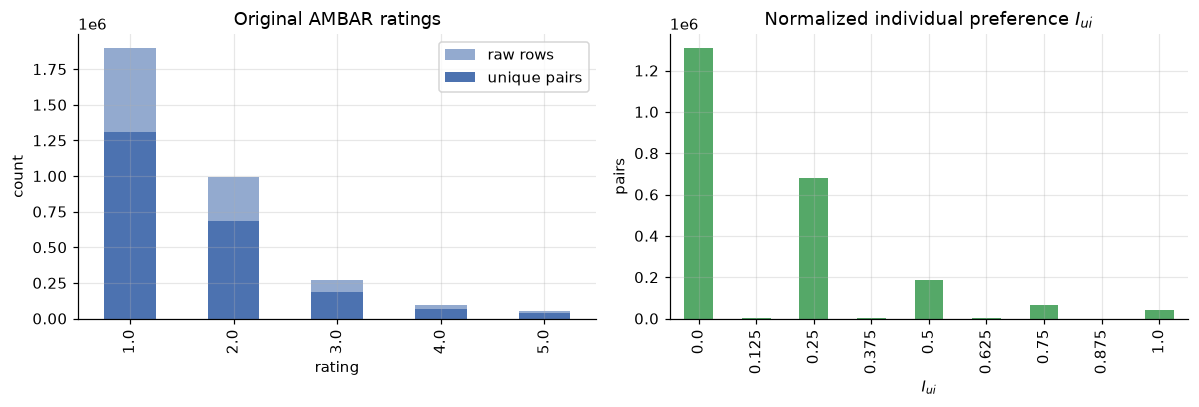

In [22]:
sample = df.sample(min(PLOT_SAMPLE_SIZE, len(df)), random_state=RANDOM_SEED)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
raw["ratings"]["rating"].value_counts().sort_index().plot.bar(ax=ax[0], color="#4C72B0", alpha=0.6, label="raw rows")
ratings["rating"].round().value_counts().sort_index().plot.bar(ax=ax[0], color="#4C72B0", label="unique pairs")
ax[0].set(title="Original AMBAR ratings", xlabel="rating", ylabel="count"); ax[0].legend()
df["individual_score"].round(3).value_counts().sort_index().plot.bar(ax=ax[1], color="#55A868")
ax[1].set(title=r"Normalized individual preference $I_{ui}$", xlabel=r"$I_{ui}$", ylabel="pairs")
save_fig(fig, "01_ratings")

Ratings are strongly skewed: about 57% of pairs have rating 1 and fewer than 5% have rating 4–5. The AMBAR
quintile mapping is applied to the cumulative listening distribution, so most tracks fall into the low levels.
$I_{ui}$ is a linear rescaling and keeps this shape. It is the main reason why many tracks tie on $I_{ui}$.

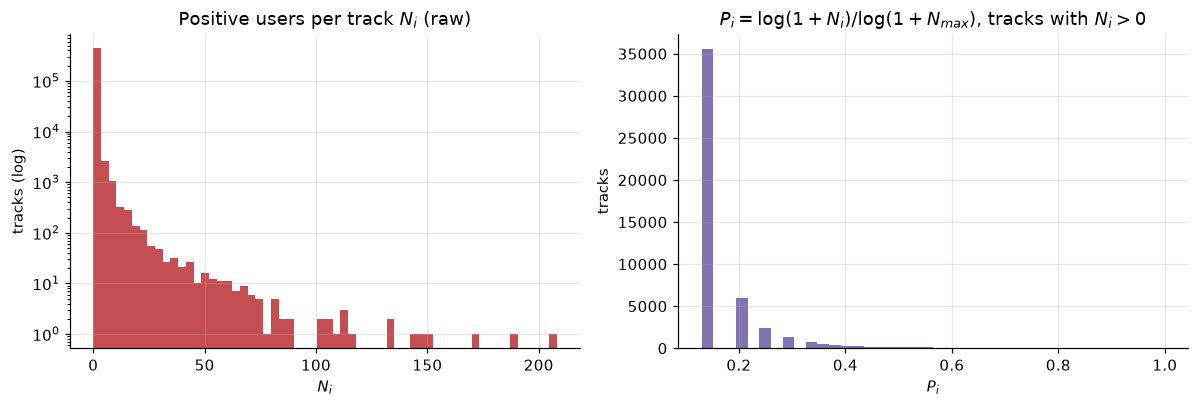

Tracks with N_i = 0 (P_i = 0) not shown on the right: 89.0%


In [23]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
npos = track_pop["n_positive"]
ax[0].hist(npos, bins=np.arange(0, npos.max() + 2) - 0.5 if npos.max() < 60 else 60, color="#C44E52")
ax[0].set(yscale="log", title=r"Positive users per track $N_i$ (raw)", xlabel=r"$N_i$", ylabel="tracks (log)")
ax[1].hist(track_pop.loc[npos > 0, "P"], bins=40, color="#8172B2")
ax[1].set(title=r"$P_i=\log(1+N_i)/\log(1+N_{max})$, tracks with $N_i>0$", xlabel=r"$P_i$", ylabel="tracks")
save_fig(fig, "02_popularity")
print(f"Tracks with N_i = 0 (P_i = 0) not shown on the right: {(npos == 0).mean():.1%}")

The raw counts follow a long-tailed distribution, and the logarithm spreads the non-zero values over $[0,1]$.
Most tracks have no positive listener, so $P_i=0$. Popularity can therefore only separate a minority of
tracks. This is an intrinsic limit on how much popularity bias it can introduce.

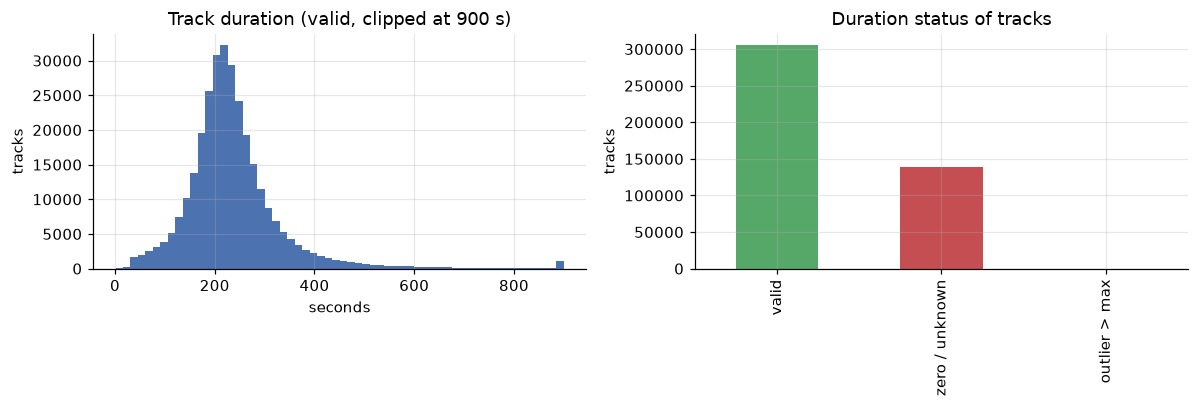

count    305134.0
mean        239.1
std         176.2
min           1.0
25%         185.0
50%         223.0
75%         269.0
max       24360.0
Name: duration_s, dtype: float64


In [24]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
valid = tracks.loc[tracks["duration_valid"], "duration_s"].astype(float)
ax[0].hist(valid.clip(upper=900), bins=60, color="#4C72B0")
ax[0].set(title="Track duration (valid, clipped at 900 s)", xlabel="seconds", ylabel="tracks")
pd.Series({"valid": int(tracks["duration_valid"].sum()), "zero / unknown": int((~tracks["duration_valid"]).sum()),
           "outlier > max": int(tracks["duration_outlier"].sum())}).plot.bar(ax=ax[1], color=["#55A868", "#C44E52", "#DD8452"])
ax[1].set(title="Duration status of tracks", ylabel="tracks")
save_fig(fig, "03_duration")
print(valid.describe().round(1))

Valid durations are centred around 3–4 minutes, typical for popular music. The large bar of zero durations
shows that about a third of tracks lack this information. It is the main data-quality limitation for a
duration-constrained playlist model.

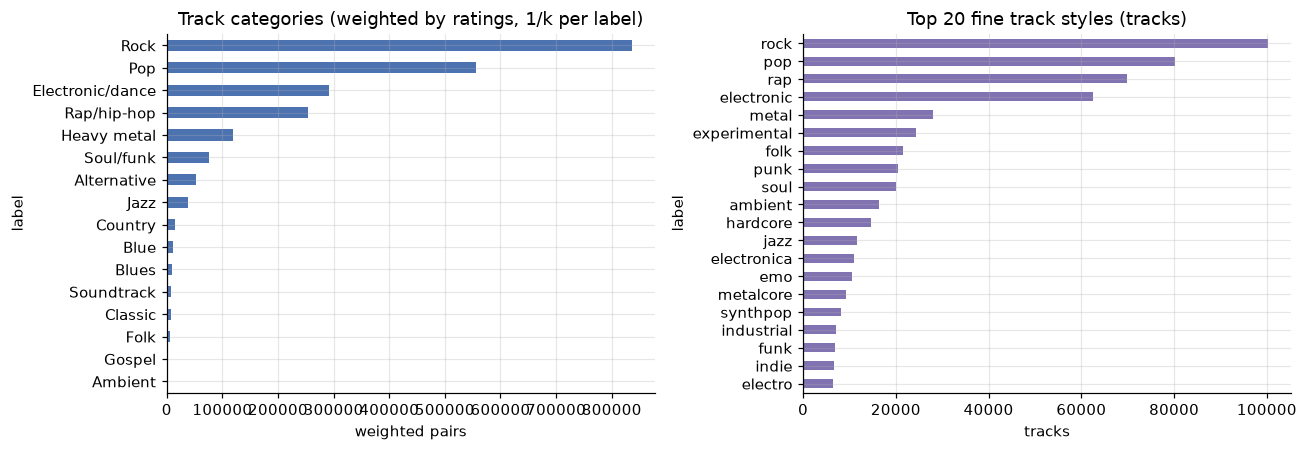

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
cat_counts = track_cats.merge(df[["track_id"]], on="track_id").groupby("label", observed=True)["weight"].sum()
cat_counts.sort_values().plot.barh(ax=ax[0], color="#4C72B0")
ax[0].set(title="Track categories (weighted by ratings, 1/k per label)", xlabel="weighted pairs")
sty_counts = track_styles["label"].value_counts().head(20)
sty_counts.sort_values().plot.barh(ax=ax[1], color="#8172B2")
ax[1].set(title="Top 20 fine track styles (tracks)", xlabel="tracks")
save_fig(fig, "04_genres")

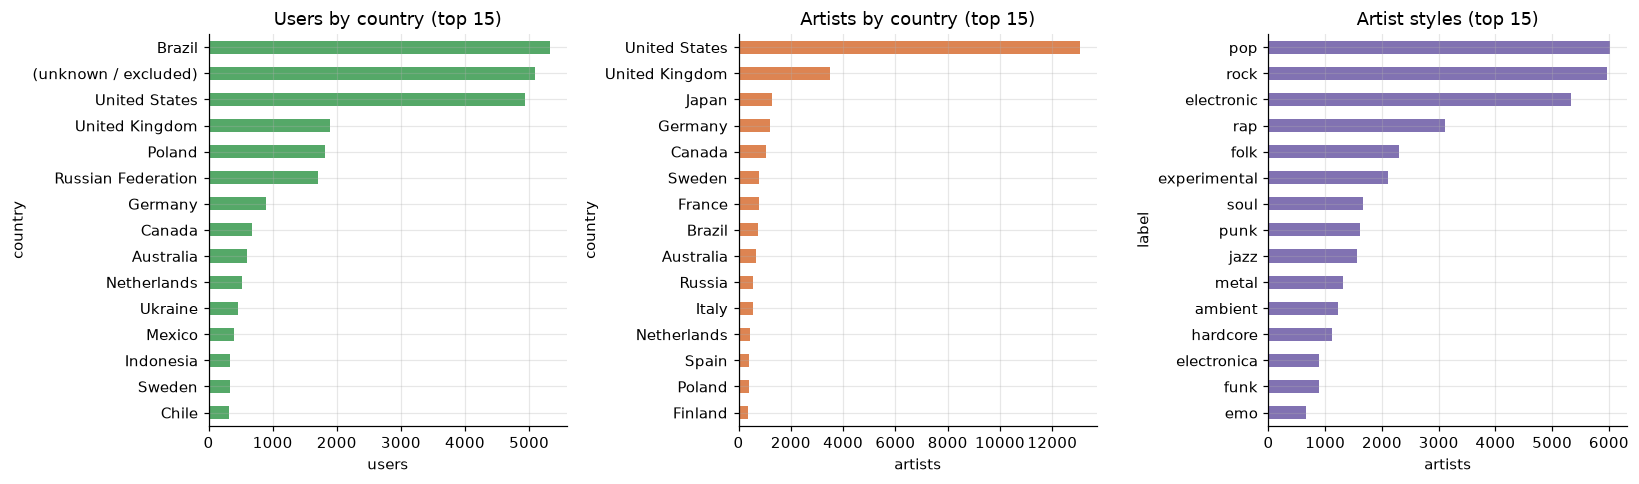

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
uc = users["country"].fillna("(unknown / excluded)").value_counts().head(15)
uc.sort_values().plot.barh(ax=ax[0], color="#55A868"); ax[0].set(title="Users by country (top 15)", xlabel="users")
artists["country"].value_counts().head(15).sort_values().plot.barh(ax=ax[1], color="#DD8452")
ax[1].set(title="Artists by country (top 15)", xlabel="artists")
artist_styles["label"].value_counts().head(15).sort_values().plot.barh(ax=ax[2], color="#8172B2")
ax[2].set(title="Artist styles (top 15)", xlabel="artists")
save_fig(fig, "05_countries_styles")

Users are concentrated in Brazil, the United States, the United Kingdom, Poland and Russia, and about 16% have
no usable country. Artists are dominated by the United States and the United Kingdom. The two distributions
differ, which illustrates why a same-country bonus would mostly reflect market structure rather than taste.

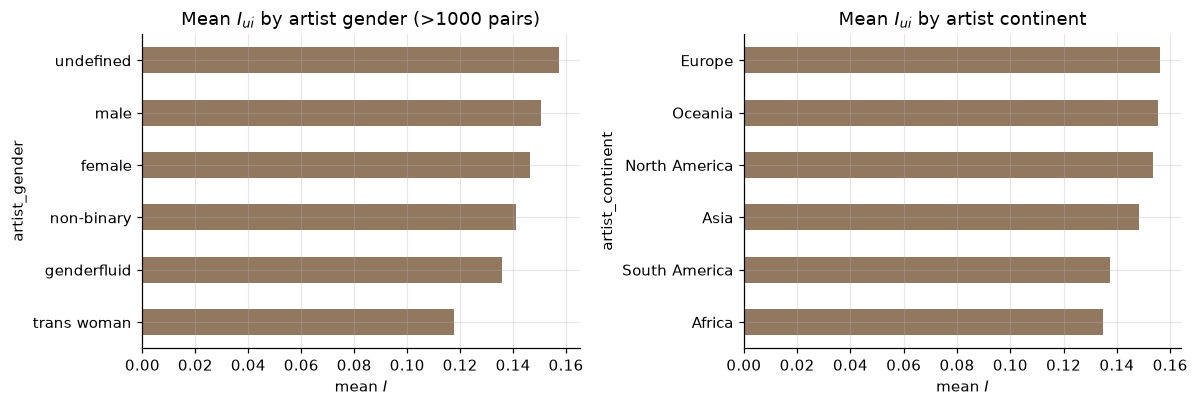

In [27]:
# Exploratory only: artist gender and continent (not part of the score)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
gtab = df.groupby(df["artist_gender"].astype(str), observed=True)["individual_score"].agg(["mean", "size"])
gtab[gtab["size"] > 1000]["mean"].sort_values().plot.barh(ax=ax[0], color="#937860")
ax[0].set(title="Mean $I_{ui}$ by artist gender (>1000 pairs)", xlabel="mean $I$")
ctab = df.groupby(df["artist_continent"].astype(str), observed=True)["individual_score"].mean().sort_values()
ctab.plot.barh(ax=ax[1], color="#937860"); ax[1].set(title="Mean $I_{ui}$ by artist continent", xlabel="mean $I$")
save_fig(fig, "06_artist_demographics")

The differences across artist gender and continent are small. Most artists have gender `undefined`, so these
attributes are kept for descriptive analysis only, as planned.

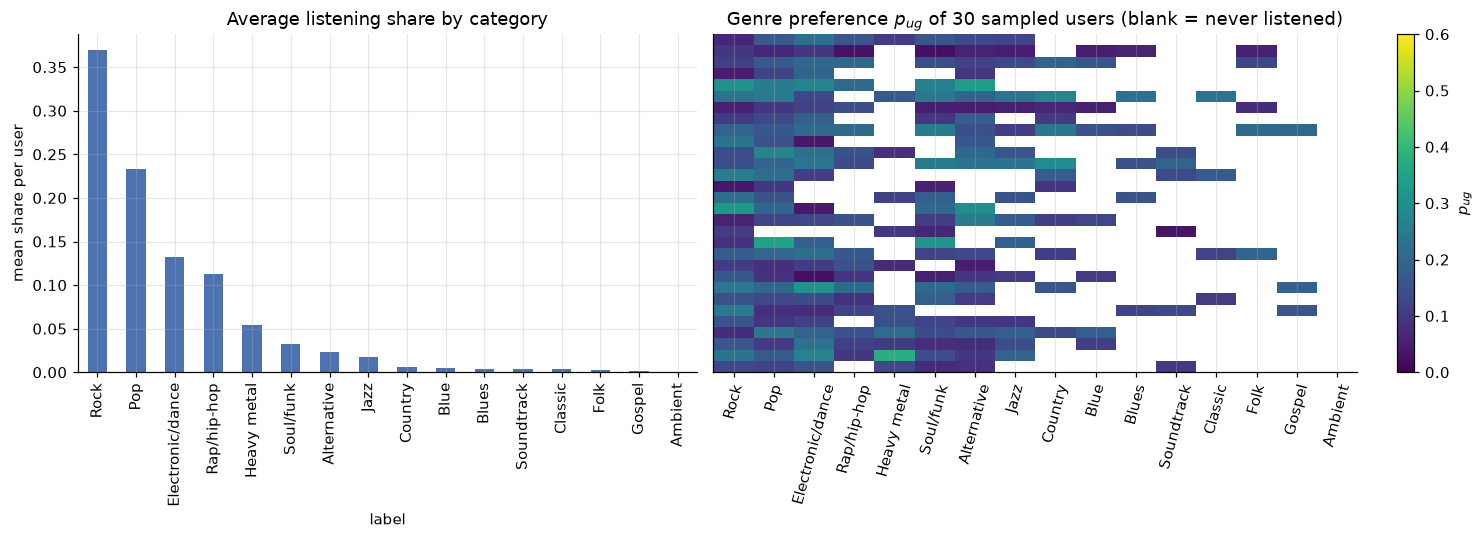

In [28]:
# User genre preference profiles (full history, shrunk to the user mean)
x = df[["user_id", "track_id", "individual_score"]].merge(track_cats, on="track_id")
prof = x.assign(wI=x["weight"] * x["individual_score"]).groupby(["user_id", "label"], observed=True)[["wI", "weight"]].sum()
umean = df.groupby("user_id")["individual_score"].mean()
prof["p"] = (prof["wI"] + BETA_PROFILE * prof.index.get_level_values(0).map(umean)) / (prof["weight"] + BETA_PROFILE)
share = (prof["weight"] / prof.groupby(level=0)["weight"].transform("sum")).unstack(fill_value=0)
pmat = prof["p"].unstack()
active = df["user_id"].value_counts().index
pick = RNG.choice(active[:5000], size=PROFILE_PLOT_USERS, replace=False)
cats_order = share.mean().sort_values(ascending=False).index

fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.3]})
share.mean()[cats_order].plot.bar(ax=ax[0], color="#4C72B0")
ax[0].set(title="Average listening share by category", ylabel="mean share per user")
im = ax[1].imshow(pmat.loc[pick, cats_order].to_numpy(), aspect="auto", cmap="viridis", vmin=0, vmax=0.6)
ax[1].set(title=f"Genre preference $p_{{ug}}$ of {PROFILE_PLOT_USERS} sampled users (blank = never listened)",
          xticks=range(len(cats_order)), yticks=[])
ax[1].set_xticklabels(cats_order, rotation=75); fig.colorbar(im, ax=ax[1], label=r"$p_{ug}$")
save_fig(fig, "07_genre_profiles")
del x

The left panel shows *what* users listen to: Rock, Pop, Electronic and Rap dominate. The heatmap shows *how
intensely* individual users listen within each category. Users with similar listening shares can still have very
different preference intensities, which justifies a per-user profile instead of global genre weights.

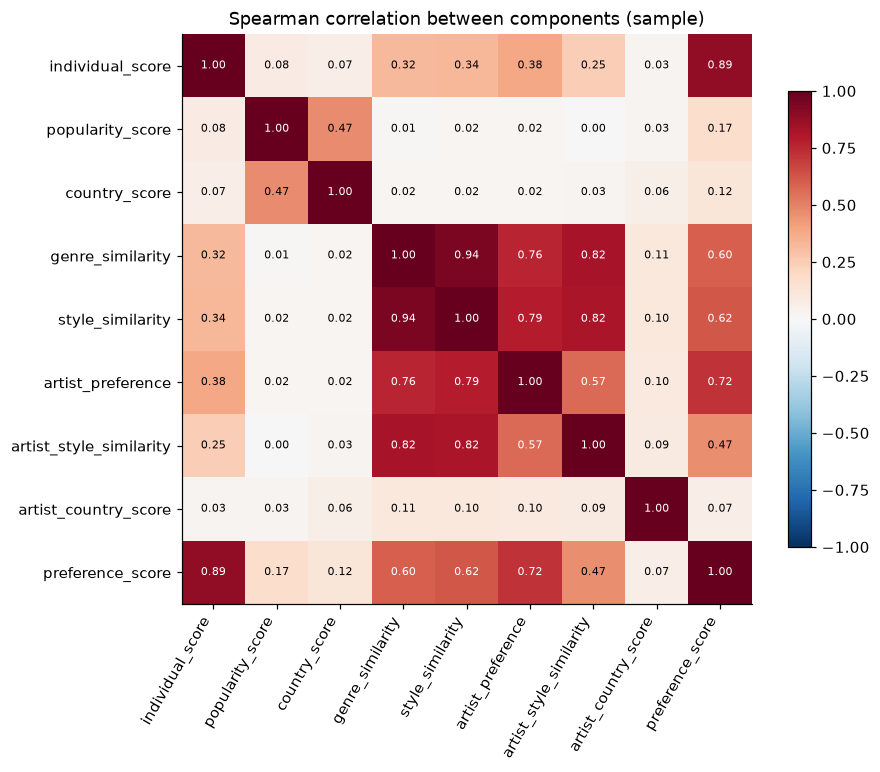

In [29]:
corr = sample[COMPONENTS + ["preference_score"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=60, ha="right"); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(corr.iat[i, j]) > 0.5 else "black")
ax.set_title("Spearman correlation between components (sample)"); ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
save_fig(fig, "08_component_correlations")

High correlations between contextual components (for example genre vs. style similarity) indicate redundancy.
NNLS resolves it by giving weight to the component with the most unique predictive value (see the ablation
table). Low correlation of the contextual components with $I_{ui}$ is expected: they never see the rating.

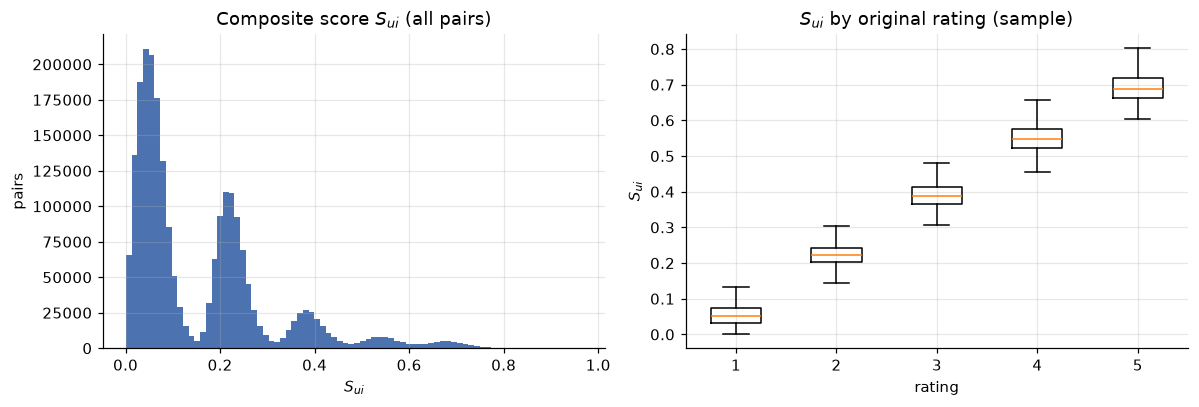

,count,mean,std,min,25%,50%,75%,max
preference_score,2283607.0,0.1582,0.1489,0.0007,0.0474,0.0886,0.2285,0.9666


In [30]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(df["preference_score"], bins=80, color="#4C72B0")
ax[0].set(title=r"Composite score $S_{ui}$ (all pairs)", xlabel=r"$S_{ui}$", ylabel="pairs")
groups = [sample.loc[sample["rating"].round() == r, "preference_score"] for r in range(1, 6)]
ax[1].boxplot(groups, showfliers=False); ax[1].set_xticks(range(1, 6)); ax[1].set_xticklabels(range(1, 6))
ax[1].set(title=r"$S_{ui}$ by original rating (sample)", xlabel="rating", ylabel=r"$S_{ui}$")
save_fig(fig, "09_composite_score")
display(df["preference_score"].describe().round(4).to_frame().T)

The composite score keeps the ordering imposed by the rating (boxes increase with the rating), while spreading
tracks *within* each rating level. This within-level spread is the tie-breaking information the optimization
model needs.

# STAGE 4 — Predicting missing ratings (user-based collaborative filtering)
## 9. Why predict, and how
If the user files contained only rated songs, the optimizer could only re-select music the user already knows.
That is a **filter bubble created before the optimization even starts**. Every user file therefore contains the
**whole candidate catalogue** (Section 10). Songs the user never rated need an estimated individual preference,
predicted from **users with similar listening histories**.

**Similarity between users.** Each user is a vector of listening intensities $r_{u\cdot}$ over all 443,921
tracks. All rated pairs are used, including tracks with unknown duration: they are not candidates, but they still
describe taste. Cosine similarity is damped when two users share few tracks (significance weighting):
$$s_{uv}=\frac{\langle r_{u\cdot},r_{v\cdot}\rangle}{\|r_{u\cdot}\|\,\|r_{v\cdot}\|}\cdot
\frac{\min(|\mathcal T_u\cap\mathcal T_v|,\gamma)}{\gamma}.$$
Only the $k$ most similar users $\mathcal N_k(u)$ are kept.

**Prediction (mean-centred, shrunk).**
$$\hat I_{ui}=\operatorname{clip}_{[0,1]}\left(\mu_u+\frac{\sum_{v\in\mathcal N_k(u),\,i\in\mathcal T_v} s_{uv}\,(I_{vi}-\mu_v)}{\sum_{v\in\mathcal N_k(u),\,i\in\mathcal T_v} s_{uv}+\lambda_{cf}}\right).$$
When no neighbour listened to $i$, the prediction is the user's own mean $\mu_u$. Nothing is invented beyond
"average for this user". The shrinkage $\lambda_{cf}$ pulls predictions supported by little evidence toward
$\mu_u$.

**Observed vs. predicted.** For rated songs the observed $I_{ui}$ is used, and only unrated songs receive
$\hat I_{ui}$. Observed values are discrete (0, 0.25, …, 1), while predictions are smooth values close to
$\mu_u$, so the score keeps more confidence in observed preferences.

In [31]:
try:
    import scipy.sparse as sp
except ImportError as exc:
    raise ImportError("scipy is required for the collaborative-filtering stage: pip install scipy") from exc

user_index = pd.Index(np.sort(df["user_id"].unique()), name="user_id")
track_index = pd.Index(np.sort(df["track_id"].unique()), name="track_id")
U_IDX = user_index.get_indexer(df["user_id"])
T_IDX = track_index.get_indexer(df["track_id"])
N_U, N_T = len(user_index), len(track_index)
I_ALL = df["individual_score"].to_numpy()
R_ALL = df["rating"].to_numpy()


def build_matrices(mask):
    """Sparse user x track matrices built from the pairs selected by `mask`.
    R: listening intensity (rating 1-5), B: indicator, C: mean-centred I, mu: user means."""
    r, c = U_IDX[mask], T_IDX[mask]
    R = sp.csr_matrix((R_ALL[mask], (r, c)), shape=(N_U, N_T))
    B = sp.csr_matrix((np.ones(mask.sum()), (r, c)), shape=(N_U, N_T))
    cnt = np.bincount(r, minlength=N_U)
    mu = np.where(cnt > 0, np.bincount(r, weights=I_ALL[mask], minlength=N_U) / np.maximum(cnt, 1), MU)
    C = sp.csr_matrix((I_ALL[mask] - mu[r], (r, c)), shape=(N_U, N_T))
    return R, B, C, mu


def neighbour_weights(Rn, B, rows):
    """Top-k significance-weighted cosine neighbours for the users in `rows` -> sparse (len(rows) x N_U)."""
    S = (Rn[rows] @ Rn.T).toarray()
    S *= np.minimum((B[rows] @ B.T).toarray(), CF_SIGNIFICANCE_GAMMA) / CF_SIGNIFICANCE_GAMMA
    S[np.arange(len(rows)), rows] = 0.0                       # a user is not its own neighbour
    k = min(CF_NEIGHBORS, N_U - 1)
    idx = np.argpartition(-S, k - 1, axis=1)[:, :k]
    val = np.take_along_axis(S, idx, axis=1)
    W = sp.csr_matrix((val.ravel(), (np.repeat(np.arange(len(rows)), k), idx.ravel())), shape=(len(rows), N_U))
    W.eliminate_zeros()
    return W


def row_normalize(R):
    norms = np.sqrt(np.asarray(R.multiply(R).sum(axis=1)).ravel())
    return sp.diags(1.0 / np.where(norms > 0, norms, 1.0)) @ R
print(f"Rating matrix: {N_U:,} users x {N_T:,} tracks, density {len(df) / (N_U * N_T):.2e}")

Rating matrix: 31,013 users x 443,921 tracks, density 1.66e-04


### 9.1 Hold-out evaluation of the predictor
For `CF_EVAL_USERS` random users, `HOLDOUT_FRACTION` of their pairs are hidden. Similarities and user means are
recomputed without them, and the hidden ratings are predicted. The predictor is compared with two simple
baselines: the user's mean, and the smoothed track mean. *Coverage* is the share of hidden pairs for which at
least one neighbour listened to the track.

In [32]:
t_cf = time.perf_counter()
eval_u = RNG.choice(N_U, size=min(CF_EVAL_USERS, N_U), replace=False)
hidden = np.isin(U_IDX, eval_u) & (RNG.random(len(df)) < HOLDOUT_FRACTION)
R_v, B_v, C_v, mu_v = build_matrices(~hidden)
Rn_v = row_normalize(R_v)

h_rows, h_cols = U_IDX[hidden], T_IDX[hidden]
pred_cf, covered = np.empty(hidden.sum()), np.empty(hidden.sum(), bool)
order = np.argsort(h_rows, kind="stable")
h_rows_s, h_cols_s = h_rows[order], h_cols[order]
for start in range(0, len(eval_u), CF_CHUNK_USERS):
    rows = np.sort(eval_u)[start:start + CF_CHUNK_USERS]
    W = neighbour_weights(Rn_v, B_v, rows)
    num, den = (W @ C_v).tocsr(), (W @ B_v).tocsr()
    sel = np.isin(h_rows_s, rows)
    local = np.searchsorted(rows, h_rows_s[sel])
    n_ = np.asarray(num[local, h_cols_s[sel]]).ravel()
    d_ = np.asarray(den[local, h_cols_s[sel]]).ravel()
    pred_cf[order[sel]] = np.clip(mu_v[h_rows_s[sel]] + n_ / (d_ + CF_SHRINK), 0, 1)
    covered[order[sel]] = d_ > 0

tr_cnt = np.asarray(B_v.sum(axis=0)).ravel()
tr_sum = np.bincount(T_IDX[~hidden], weights=I_ALL[~hidden], minlength=N_T)
track_mean_v = (tr_sum + KAPPA_TRACK * MU) / (tr_cnt + KAPPA_TRACK)
hold = df.loc[hidden, ["user_id", "individual_score", "positive"]].reset_index(drop=True)
cf_eval = pd.DataFrame([evaluate(hold, mu_v[h_rows], "baseline: user mean"),
                        evaluate(hold, track_mean_v[h_cols], "baseline: smoothed track mean"),
                        evaluate(hold, pred_cf, "user-based CF (adopted)"),
                        evaluate(hold[covered].reset_index(drop=True), pred_cf[covered], "user-based CF, covered pairs only")
                        ]).set_index("model").round(4)
REPORT["cf_evaluation"] = {"hidden_pairs": int(hidden.sum()), "coverage": round(float(covered.mean()), 4),
                           "metrics": cf_eval.reset_index().to_dict(orient="records")}
supported = df.loc[hidden, "track_id"].map(df.groupby("track_id").size()).ge(MIN_LISTENERS).to_numpy()
REPORT["cf_evaluation"]["coverage_tracks_with_min_listeners"] = round(float(covered[supported].mean()), 4)
print(f"{hidden.sum():,} hidden pairs of {len(eval_u):,} users | coverage {covered.mean():.1%} overall, "
      f"{covered[supported].mean():.1%} for tracks with >= {MIN_LISTENERS} listeners | {time.perf_counter() - t_cf:.1f} s")
display(cf_eval)
del R_v, B_v, C_v, Rn_v

43,991 hidden pairs of 3,000 users | coverage 52.7% overall, 73.4% for tracks with >= 20 listeners | 3.9 s


,RMSE,global_spearman,AUC_positive,within_user_spearman,users_in_within_metric
model,,,,,
baseline: user mean,0.2121,0.3007,0.6509,NaN,0
baseline: smoothed track mean,0.2205,0.0790,0.5765,0.0709,2846
user-based CF (adopted),0.2091,0.3385,0.7034,0.1350,2790
"user-based CF, covered pairs only",0.2211,0.3645,0.7168,0.1777,2471


**Reading the table.** The user mean cannot rank a user's own tracks (within-user ρ is undefined, so it is shown
as NaN), and RMSE alone rewards predicting the average. What matters is whether the predictor *orders* tracks
correctly: the global Spearman ρ, the AUC for positives and the within-user Spearman ρ. On covered pairs the
neighbours' evidence is used. On uncovered pairs the predictor honestly falls back to $\mu_u$. Coverage is much
higher for tracks with at least `MIN_LISTENERS` listeners, which are exactly the songs of the catalogue in
Section 10.

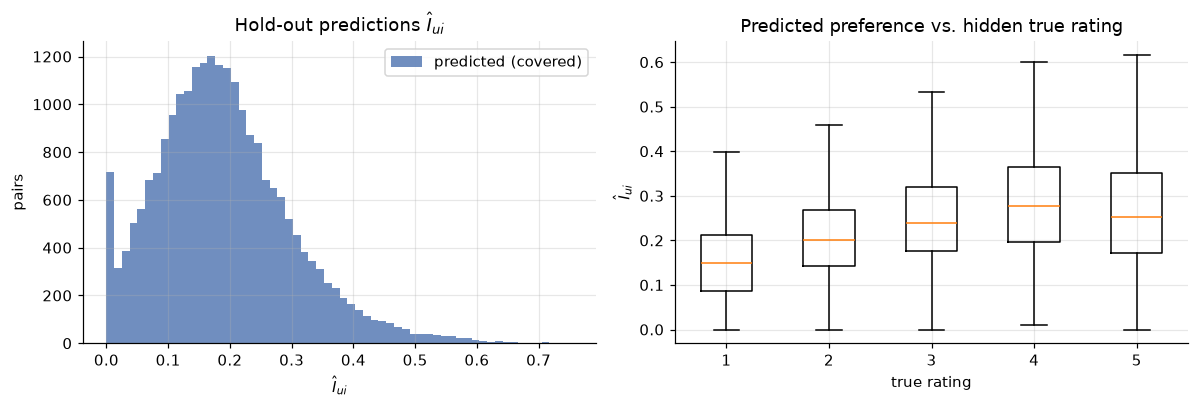

In [33]:
# Final similarity structure: all pairs visible
R_f, B_f, C_f, mu_f = build_matrices(np.ones(len(df), bool))
Rn_f = row_normalize(R_f)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(pred_cf[covered], bins=60, color="#4C72B0", alpha=0.8, label="predicted (covered)")
ax[0].set(title=r"Hold-out predictions $\hat I_{ui}$", xlabel=r"$\hat I_{ui}$", ylabel="pairs"); ax[0].legend()
g = pd.DataFrame({"rating": df.loc[hidden, "rating"].round().to_numpy(), "pred": pred_cf})[covered]
ax[1].boxplot([g.loc[g.rating == r, "pred"] for r in range(1, 6)], showfliers=False)
ax[1].set_xticks(range(1, 6)); ax[1].set_xticklabels(range(1, 6))
ax[1].set(title="Predicted preference vs. hidden true rating", xlabel="true rating", ylabel=r"$\hat I_{ui}$")
save_fig(fig, "10_cf_evaluation")

Median predictions increase from true rating 1 to 4, with rating 5 at about the level of 4. Neighbours'
listening carries real signal about how
much a user will listen to a track they have not rated. Predictions stay compressed near the user's mean, which
is expected from a shrunk estimator with sparse data. This is also why observed ratings keep more weight than
predictions in the final score.

# STAGE 5 — Candidate catalogue and genre indicators
## 10. One shared catalogue for every user
A song is a candidate if:

1. its duration is **known and positive**. Durations of 0, negative or missing are **never** allowed, because
   duration is a constraint of the model;
2. it is not a duration outlier (> `MAX_REASONABLE_DURATION_S`), if `EXCLUDE_DURATION_OUTLIERS = True`;
3. it has at least `MIN_LISTENERS` distinct listeners, so that its popularity, country and collaborative
   estimates rest on real evidence.

Every user file contains **all** catalogue songs, both rated and unrated. No per-user pre-selection is applied.

In [34]:
listeners = df.groupby("track_id")["user_id"].size()
cat_mask = (tracks["duration_valid"]
            & tracks["track_id"].map(listeners).fillna(0).ge(MIN_LISTENERS).to_numpy())
if EXCLUDE_DURATION_OUTLIERS:
    cat_mask &= ~tracks["duration_outlier"]
catalogue = (tracks.loc[cat_mask, ["track_id", "artist_id", "duration_s"]]
             .rename(columns={"track_id": "song_id", "duration_s": "duration"})
             .sort_values("song_id").reset_index(drop=True))
catalogue["duration"] = catalogue["duration"].astype("int64")
assert catalogue["duration"].gt(0).all() and catalogue["duration"].notna().all()

# Genre indicator columns: 1 if the song has the category, 0 otherwise
def genre_col(label):
    return "genre_" + "".join(ch if ch.isalnum() else "_" for ch in str(label).lower()).strip("_").replace("__", "_")

cg = track_cats[track_cats["track_id"].isin(catalogue["song_id"])].copy()
cg["label"] = cg["label"].astype(str)
order_lbl = cg["label"].value_counts().index.tolist()            # most frequent first
GENRE_MAP = {lbl: genre_col(lbl) for lbl in order_lbl}
assert len(set(GENRE_MAP.values())) == len(GENRE_MAP), "genre column names collide"
onehot = (pd.crosstab(cg["track_id"], cg["label"]).clip(upper=1).astype("int8")
          .reindex(columns=order_lbl).rename(columns=GENRE_MAP))
GENRE_COLS = list(GENRE_MAP.values())
catalogue = catalogue.merge(onehot, left_on="song_id", right_index=True, how="left", validate="one_to_one")
assert catalogue[GENRE_COLS].notna().all().all(), "catalogue song without genre"
catalogue[GENRE_COLS] = catalogue[GENRE_COLS].astype("int8")
assert catalogue[GENRE_COLS].sum(axis=1).ge(1).all(), "every song needs at least one genre"

M = len(catalogue)
REPORT["catalogue"] = {
    "songs": M, "min_listeners": MIN_LISTENERS, "excluded_outliers": bool(EXCLUDE_DURATION_OUTLIERS),
    "genre_columns": GENRE_MAP, "total_duration_h": round(catalogue["duration"].sum() / 3600, 1),
    "songs_per_genre": catalogue[GENRE_COLS].sum().astype(int).to_dict(),
}
print(f"Catalogue: {M:,} songs | {len(GENRE_COLS)} genre columns | "
      f"{(catalogue[GENRE_COLS].sum(axis=1) > 1).mean():.1%} of songs have several genres")
display(pd.Series(GENRE_MAP, name="column").to_frame().assign(songs=catalogue[GENRE_COLS].sum().to_numpy()))
with open(PROCESSED_DIR / "genre_columns.json", "w", encoding="utf-8") as fh:
    json.dump(GENRE_MAP, fh, indent=2)

Catalogue: 13,931 songs | 15 genre columns | 31.4% of songs have several genres


,column,songs
Rock,genre_rock,6441
Pop,genre_pop,4867
Electronic/dance,genre_electronic_dance,2685
Rap/hip-hop,genre_rap_hip_hop,1649
Heavy metal,genre_heavy_metal,960
Soul/funk,genre_soul_funk,695
Alternative,genre_alternative,507
Jazz,genre_jazz,353
Blue,genre_blue,162
Country,genre_country,151


A multi-genre song such as `Rock|Pop` has a 1 in **both** `genre_rock` and `genre_pop`. Labels are never kept as
combined strings. `genre_blue` is the AMBAR category `Blue` (mostly R&B, see Section 3.2). The mapping from
labels to column names is saved in `genre_columns.json`.

## 11. Preference score for every (user, catalogue song)
For each exported user and **every** catalogue song, all components are computed and combined with the weights
from Section 7:
$$S_{ui}=w_1\,\tilde I_{ui}+\sum_k w_k X^k_{ui},\qquad
\tilde I_{ui}=\begin{cases}I_{ui}&\text{song rated by }u\\ \hat I_{ui}&\text{otherwise (CF prediction)}\end{cases}$$

| Component | Unrated song (from the full history) | Rated song |
|---|---|---|
| individual | CF prediction $\hat I_{ui}$ | observed $I_{ui}$ |
| popularity | $\log(1+N_i)/\log(1+N_{\max})$ | LOO value (Sec. 5) |
| country | smoothed mean of $I$ among users of $c(u)$ | LOO value |
| genre / style similarity | user profile · song labels | LOO value |
| artist preference | shrunk mean of the user's ratings of the artist ($\mu_u$ if never heard) | LOO value |
| artist style similarity | profile over other artists' styles | LOO value |
| artist country | smoothed mean for (user country, artist country) | LOO value |

The formula for unrated songs is exactly the LOO formula, because an unrated song has no own rating to remove.
Everything is computed with dense matrix operations over chunks of users. No loop runs over songs.

**Which users are exported** is controlled by `EXPORT_USERS` / `N_EXPORT_USERS`. Each file has $M$ rows (the
whole catalogue), so exporting all 31,000 users would need tens of GB.

In [35]:
# ---- users to export -------------------------------------------------------
if EXPORT_USERS is None:
    export_ids = np.sort(RNG.choice(user_index.to_numpy(), size=min(N_EXPORT_USERS, N_U), replace=False))
elif isinstance(EXPORT_USERS, str) and EXPORT_USERS == "all":
    export_ids = user_index.to_numpy()
else:
    export_ids = np.array(sorted(set(int(u) for u in EXPORT_USERS)))
    unknown = set(export_ids) - set(user_index)
    if unknown:
        raise KeyError(f"EXPORT_USERS contains ids without ratings: {sorted(unknown)[:10]}")
exp_rows = user_index.get_indexer(export_ids)
est_gb = len(export_ids) * M * (12 + 2 * len(GENRE_COLS)) / 1e9
print(f"Exporting {len(export_ids):,} users x {M:,} songs (estimated CSV size about {est_gb:.2f} GB)")
if est_gb > 20:
    warnings.warn("Very large export requested; consider a smaller N_EXPORT_USERS.")

# ---- catalogue-level lookups ------------------------------------------------
cat_ids = catalogue["song_id"].to_numpy()
cat_tcol = track_index.get_indexer(cat_ids)                      # column in the rating matrix
assert (cat_tcol >= 0).all()
cat_artist = catalogue["artist_id"].to_numpy()
tp = track_pop.reindex(cat_ids)
pop_cat = (np.log1p(tp["n_positive"]) / np.log1p(N_MAX)).to_numpy()
m_cat = tp["smoothed_mean"].to_numpy()

countries = pd.Index(sorted(df["user_country"].dropna().astype(str).unique()))
kc = df["user_country"].notna().to_numpy() & np.isin(df["track_id"].to_numpy(), cat_ids)
ci = countries.get_indexer(df.loc[kc, "user_country"].astype(str))
cj = pd.Index(cat_ids).get_indexer(df.loc[kc, "track_id"])
CS = np.zeros((len(countries), M)); CN = np.zeros((len(countries), M))
np.add.at(CS, (ci, cj), I_ALL[kc]); np.add.at(CN, (ci, cj), 1.0)
user_ctry = df.groupby("user_id")["user_country"].first().reindex(user_index).astype("string")

art_ctry_idx = pd.Index(sorted(artists["country"].dropna().unique()))
k2 = df["user_country"].notna().to_numpy() & df["artist_country"].notna().to_numpy()
AC_S = np.zeros((len(countries), len(art_ctry_idx))); AC_N = np.zeros_like(AC_S)
np.add.at(AC_S, (countries.get_indexer(df.loc[k2, "user_country"].astype(str)),
                 art_ctry_idx.get_indexer(df.loc[k2, "artist_country"].astype(str))), I_ALL[k2])
np.add.at(AC_N, (countries.get_indexer(df.loc[k2, "user_country"].astype(str)),
                 art_ctry_idx.get_indexer(df.loc[k2, "artist_country"].astype(str))), 1.0)
cat_art_ctry = art_ctry_idx.get_indexer(catalogue["artist_id"].map(artists.set_index("artist_id")["country"]))

def label_matrix(labels, ids, id_col):
    """Sparse (len(ids) x n_labels) weight matrix from an exploded label table."""
    lab_index = pd.Index(labels["label"].astype(str).unique())
    sub = labels[labels[id_col].isin(ids)]
    r = pd.Index(ids).get_indexer(sub[id_col]); c = lab_index.get_indexer(sub["label"].astype(str))
    return sp.csr_matrix((sub["weight"].to_numpy(), (r, c)), shape=(len(ids), len(lab_index))), lab_index

T_style, style_index = label_matrix(track_styles, track_index.to_numpy(), "track_id")   # all tracks x styles
T_cat, cat_index = label_matrix(track_cats, track_index.to_numpy(), "track_id")
artist_index = pd.Index(np.sort(df["artist_id"].unique()))
A_sty, astyle_index = label_matrix(artist_styles, artist_index.to_numpy(), "artist_id")
UA_cols = artist_index.get_indexer(df["artist_id"])
I_UA = sp.csr_matrix((I_ALL, (U_IDX, UA_cols)), shape=(N_U, len(artist_index)))   # sum of I per user-artist
N_UA = sp.csr_matrix((np.ones(len(df)), (U_IDX, UA_cols)), shape=(N_U, len(artist_index)))
cat_acol = artist_index.get_indexer(cat_artist)
assert (cat_acol >= 0).all()
# style slots of catalogue artists (artists have few styles -> loop over slot position, not over songs)
A_sty_cat = A_sty[cat_acol].tocsr()
max_slots = int(np.diff(A_sty_cat.indptr).max())
print(f"Lookups ready: {len(countries)} user countries, {len(style_index)} track styles, "
      f"{len(astyle_index)} artist styles, max {max_slots} styles per artist")

Exporting 100 users x 13,931 songs (estimated CSV size about 0.06 GB)
Lookups ready: 221 user countries, 282 track styles, 220 artist styles, max 5 styles per artist


In [36]:
B_cat = B_f.tocsc()[:, cat_tcol].tocsr()
C_cat = C_f.tocsc()[:, cat_tcol].tocsr()
I_M = sp.csr_matrix((I_ALL, (U_IDX, T_IDX)), shape=(N_U, N_T))     # observed I, user x track

def score_chunk(rows):
    """Return dict of dense (len(rows) x M) component matrices and the rated mask."""
    n = len(rows)
    mu_u = mu_f[rows][:, None]
    out = {}
    # individual: CF prediction, then observed values for rated songs
    W = neighbour_weights(Rn_f, B_f, rows)
    num, den = (W @ C_cat).toarray(), (W @ B_cat).toarray()
    out["individual_score"] = np.clip(mu_u + num / (den + CF_SHRINK), 0, 1)
    out["popularity_score"] = np.broadcast_to(pop_cat, (n, M)).copy()
    # country
    cidx = countries.get_indexer(user_ctry.iloc[rows].fillna("__none__").astype(str))
    cs = np.broadcast_to(m_cat, (n, M)).copy()
    k = cidx >= 0
    cs[k] = (CS[cidx[k]] + LAMBDA_COUNTRY * m_cat) / (CN[cidx[k]] + LAMBDA_COUNTRY)
    out["country_score"] = cs
    # genre / style similarity: shrunk user profile . song label weights
    for name, T, lab in (("genre_similarity", T_cat, cat_index), ("style_similarity", T_style, style_index)):
        S_ = (I_M[rows] @ T).toarray()
        W_ = (B_f[rows] @ T).toarray()
        prof = (S_ + BETA_PROFILE * mu_u) / (W_ + BETA_PROFILE)
        out[name] = (T[cat_tcol] @ prof.T).T
    # artist preference
    s_ua, n_ua = I_UA[rows][:, cat_acol].toarray(), N_UA[rows][:, cat_acol].toarray()
    out["artist_preference"] = (s_ua + BETA_PROFILE * mu_u) / (n_ua + BETA_PROFILE)
    # artist style similarity (profile from other artists)
    S_us, N_us = (I_UA[rows] @ A_sty).toarray(), (N_UA[rows] @ A_sty).toarray()
    acc = np.zeros((n, M))
    starts, ends = A_sty_cat.indptr[:-1], A_sty_cat.indptr[1:]
    for j in range(max_slots):
        has = (ends - starts) > j
        sidx = np.where(has, A_sty_cat.indices[np.minimum(starts + j, len(A_sty_cat.indices) - 1)], 0)
        w = np.where(has, A_sty_cat.data[np.minimum(starts + j, len(A_sty_cat.data) - 1)], 0.0)
        q = (S_us[:, sidx] - w * s_ua + BETA_PROFILE * mu_u) / (N_us[:, sidx] - w * n_ua + BETA_PROFILE)
        acc += w * q
    out["artist_style_similarity"] = acc
    # artist country affinity
    ac = np.full((n, M), MU)
    kk = (cidx >= 0)
    valid_a = cat_art_ctry >= 0
    blk = (AC_S[cidx[kk]][:, cat_art_ctry] + LAMBDA_ART_CTRY * MU) / (AC_N[cidx[kk]][:, cat_art_ctry] + LAMBDA_ART_CTRY)
    blk[:, ~valid_a] = MU
    ac[kk] = blk
    out["artist_country_score"] = ac
    # rated songs: replace every component with the observed / LOO values from Section 5
    sel = np.isin(U_IDX, rows) & np.isin(T_IDX, cat_tcol)
    rr = np.searchsorted(rows, U_IDX[sel])
    cc = pd.Index(cat_tcol).get_indexer(T_IDX[sel])
    for c in COMPONENTS:
        out[c][rr, cc] = df[c].to_numpy()[sel]
    rated = np.zeros((n, M), bool); rated[rr, cc] = True
    return out, rated

t_s = time.perf_counter()
exp_rows_sorted = np.sort(exp_rows)
for old in USERS_OUT_DIR.glob("user_*.csv"):          # remove files from previous runs
    old.unlink()
float_fmt = f"%.{CSV_FLOAT_DECIMALS}f"
base_cols = catalogue[["song_id", "duration"] + GENRE_COLS]
parts, comp_samples, n_files = [], [], 0
for start in range(0, len(exp_rows_sorted), EXPORT_CHUNK_USERS):
    rows = exp_rows_sorted[start:start + EXPORT_CHUNK_USERS]
    comps, rated = score_chunk(rows)
    for c in COMPONENTS:
        v = comps[c]
        assert np.isfinite(v).all() and (v >= -1e-9).all() and (v <= 1 + 1e-9).all(), f"{c} out of range"
    score = np.clip(sum(WEIGHTS[c] * comps[c] for c in COMPONENTS), 0.0, 1.0)
    for local, r in enumerate(rows):
        uid = int(user_index[r])
        user_df = base_cols.assign(preference_score=score[local]).sort_values(
            "preference_score", ascending=False, kind="mergesort")
        user_df.to_csv(USERS_OUT_DIR / f"user_{uid}.csv", index=False, float_format=float_fmt)
        n_files += 1
        parts.append(pd.DataFrame({"user_id": uid, "song_id": cat_ids, "preference_score": score[local],
                                   "is_rated": rated[local]}))
    pick = RNG.choice(len(rows) * M, size=min(20_000, len(rows) * M), replace=False)
    comp_samples.append(pd.DataFrame({c: comps[c].ravel()[pick] for c in COMPONENTS})
                        .assign(is_rated=rated.ravel()[pick], preference_score=score.ravel()[pick]))
    print(f"  users {start + len(rows):>6,}/{len(exp_rows_sorted):,} scored and written")

final = pd.concat(parts, ignore_index=True).merge(catalogue[["song_id", "duration"] + GENRE_COLS], on="song_id",
                                                  how="left", validate="many_to_one")
final = final[["user_id", "song_id", "duration"] + GENRE_COLS + ["preference_score", "is_rated"]]
comp_sample = pd.concat(comp_samples, ignore_index=True)
PARQUET_PATH = PROCESSED_DIR / "final_user_song_scores.parquet"
final.to_parquet(PARQUET_PATH, engine="pyarrow", index=False)
catalogue[["song_id", "duration"] + GENRE_COLS].to_csv(PROCESSED_DIR / "catalogue.csv", index=False)
print(f"Wrote {n_files:,} user files and {len(final):,} scored pairs in {time.perf_counter() - t_s:.1f} s")

  users    100/100 scored and written
Wrote 100 user files and 1,393,100 scored pairs in 6.7 s


### 11.1 Does the full catalogue break the filter bubble?
For each exported user, the top 50 songs by score are compared with the songs the user already rated:
* how many of the top 50 are **new** (never rated);
* how many distinct genres the top 50 cover, compared with the user's rated catalogue songs.

,new_songs_in_top,genres_in_top,genres_in_rated_history
count,100.00,100.00,100.00
mean,40.16,6.65,5.42
std,5.98,1.72,2.07
min,21.00,3.00,1.00
25%,36.75,5.00,4.00
50%,40.50,7.00,5.00
75%,45.00,8.00,7.00
max,50.00,11.00,11.00


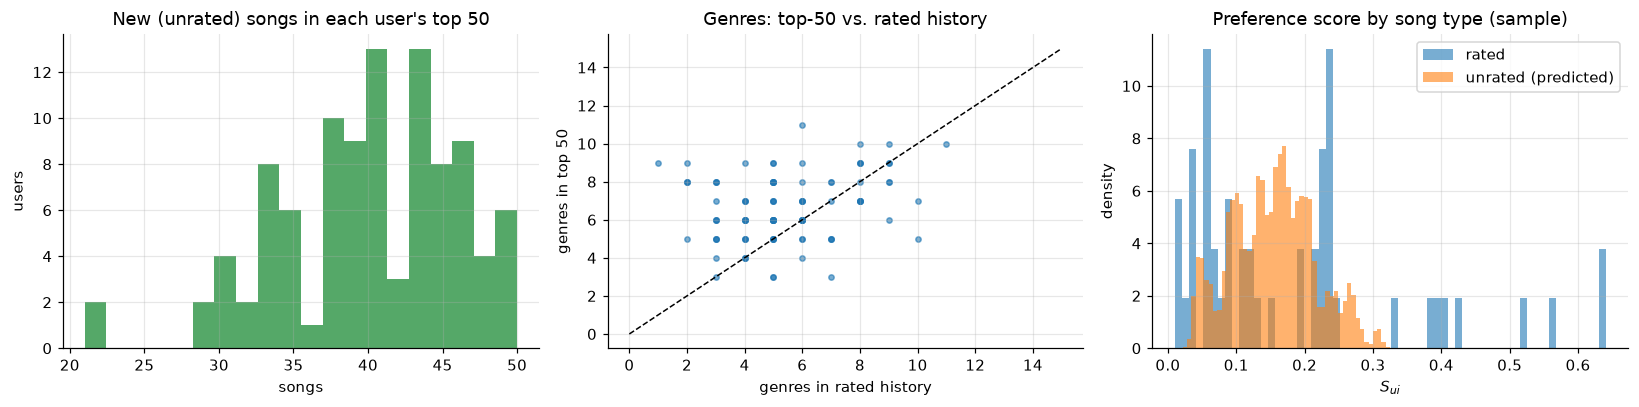

In [37]:
TOP_K_BUBBLE = 50
f_sorted = final.sort_values(["user_id", "preference_score"], ascending=[True, False])
top = f_sorted.groupby("user_id").head(TOP_K_BUBBLE)
bubble = pd.DataFrame({
    "new_songs_in_top": top.groupby("user_id")["is_rated"].apply(lambda s: (~s).sum()),
    "genres_in_top": top.groupby("user_id")[GENRE_COLS].max().sum(axis=1),
    "genres_in_rated_history": final[final["is_rated"]].groupby("user_id")[GENRE_COLS].max().sum(axis=1),
}).fillna(0)
REPORT["bubble_diagnostic"] = bubble.describe().round(2).to_dict()
display(bubble.describe().round(2))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(bubble["new_songs_in_top"], bins=20, color="#55A868")
ax[0].set(title=f"New (unrated) songs in each user's top {TOP_K_BUBBLE}", xlabel="songs", ylabel="users")
ax[1].scatter(bubble["genres_in_rated_history"], bubble["genres_in_top"], s=12, alpha=0.6)
lim = [0, len(GENRE_COLS)]; ax[1].plot(lim, lim, "k--", lw=1)
ax[1].set(title="Genres: top-50 vs. rated history", xlabel="genres in rated history", ylabel=f"genres in top {TOP_K_BUBBLE}")
for flag, lab in ((True, "rated"), (False, "unrated (predicted)")):
    ax[2].hist(comp_sample.loc[comp_sample.is_rated == flag, "preference_score"], bins=60, alpha=0.6,
               density=True, label=lab)
ax[2].set(title="Preference score by song type (sample)", xlabel=r"$S_{ui}$", ylabel="density"); ax[2].legend()
save_fig(fig, "11_filter_bubble")

**Reading the panels (reference run, 100 users).** On average about 40 of each user's top 50 songs are songs
the user has never rated. The optimizer is therefore not limited to known music. In the middle panel, most
points lie above the diagonal: the top 50 cover more genres (≈ 6.7 on average) than the user's rated catalogue
songs (≈ 5.4). In the right panel, known songs rated 3–5 keep the highest scores, because observed preference
weighs most. Predicted songs compete with, and often outrank, known songs rated 1–2, which the user listened to
least. That is the intended balance between confidence in observed preferences and exploration.

# STAGE 6 — Final validation
## 12. Assertions and processing report

In [38]:
checks = {}
def check(name, cond):
    checks[name] = bool(cond)
    assert cond, f"VALIDATION FAILED: {name}"

USER_CSV_COLS = ["song_id", "duration"] + GENRE_COLS + ["preference_score"]
check("1. (user, song) pairs unique", not final.duplicated(["user_id", "song_id"]).any())
check("2. durations positive, integer, never missing",
      final["duration"].notna().all() and (final["duration"] > 0).all()
      and pd.api.types.is_integer_dtype(final["duration"]))
check("3. genre columns binary", final[GENRE_COLS].isin([0, 1]).all().all())
check("4. every song has >= 1 genre", (catalogue[GENRE_COLS].sum(axis=1) >= 1).all())
check("5. preference score finite, in [0,1]", np.isfinite(final["preference_score"]).all()
      and final["preference_score"].between(0, 1).all())
check("6. song ids valid", final["song_id"].isin(tracks["track_id"]).all())
check("7. every user has the full catalogue", (final.groupby("user_id").size() == M).all())
files = sorted(USERS_OUT_DIR.glob("user_*.csv"))
check("8. one file per exported user", len(files) == len(export_ids) == final["user_id"].nunique())

samp = RNG.choice(files, size=min(VALIDATION_SAMPLE_FILES, len(files)), replace=False)
final_idx = final.set_index(["user_id", "song_id"])["preference_score"]
for f in samp:
    u = pd.read_csv(f)
    uid = int(f.stem.split("_")[1])
    assert list(u.columns) == USER_CSV_COLS, f"{f.name}: unexpected columns"
    assert len(u) == M and u["song_id"].is_unique and u["preference_score"].is_monotonic_decreasing
    assert (u["duration"] > 0).all() and u[GENRE_COLS].isin([0, 1]).all().all()
    ref = final_idx.loc[uid].reindex(u["song_id"]).to_numpy()
    assert np.allclose(u["preference_score"].to_numpy(), ref, atol=10 ** -CSV_FLOAT_DECIMALS)
checks["9. sampled user files load independently and match"] = True

total_rows = 0
for f in files:
    with open(f, "rb") as fh:
        total_rows += sum(1 for _ in fh) - 1
check("10. rows in all files = rows in final dataset", total_rows == len(final))
display(pd.Series(checks, name="passed").to_frame())

,passed
"1. (user, song) pairs unique",True
"2. durations positive, integer, never missing",True
3. genre columns binary,True
4. every song has >= 1 genre,True
"5. preference score finite, in [0,1]",True
6. song ids valid,True
7. every user has the full catalogue,True
8. one file per exported user,True
9. sampled user files load independently and match,True
10. rows in all files = rows in final dataset,True


In [39]:
out_size = sum(f.stat().st_size for f in files)
REPORT.update({
    "final_dimensions": {"final_rows": len(final), "final_columns": final.shape[1],
                         "catalogue_songs": M, "exported_users": int(len(export_ids))},
    "entities_after_cleaning": {"users": N_U, "rated_tracks": N_T, "artists": int(df["artist_id"].nunique())},
    "preference_score_stats": final["preference_score"].describe().round(5).to_dict(),
    "share_rated_pairs_in_final": round(float(final["is_rated"].mean()), 5),
    "exported_user_csv_files": len(files),
    "storage": {"parquet": human_size(PARQUET_PATH.stat().st_size), "user_csv_total": human_size(out_size)},
    "validation_checks": checks,
    "runtime_s": round(time.perf_counter() - T0, 1),
    "config": {"POSITIVE_THRESHOLD": POSITIVE_THRESHOLD, "KAPPA_TRACK": KAPPA_TRACK, "LAMBDA_COUNTRY": LAMBDA_COUNTRY,
               "BETA_PROFILE": BETA_PROFILE, "LAMBDA_ART_CTRY": LAMBDA_ART_CTRY, "W_INDIVIDUAL": W_INDIVIDUAL,
               "WEIGHT_MODE": WEIGHT_MODE, "MIN_LISTENERS": MIN_LISTENERS, "CF_NEIGHBORS": CF_NEIGHBORS,
               "CF_SIGNIFICANCE_GAMMA": CF_SIGNIFICANCE_GAMMA, "CF_SHRINK": CF_SHRINK, "RANDOM_SEED": RANDOM_SEED},
})
with open(PROCESSED_DIR / "processing_report.json", "w", encoding="utf-8") as fh:
    json.dump(REPORT, fh, indent=2, default=str)

summary = pd.DataFrame([
    ("Raw rating rows", REPORT["ratings_cleaning"]["raw_rows"]),
    ("Exact duplicate rating rows collapsed", REPORT["ratings_cleaning"]["exact_duplicate_rows_collapsed"]),
    ("Conflicting pairs averaged", REPORT["ratings_cleaning"]["conflicting_pairs_averaged"]),
    ("Unique user-track pairs (listening history)", len(df)),
    ("Tracks with unknown duration (history only, never candidates)", REPORT["tracks_cleaning"]["duration_zero_set_missing"]),
    ("Duplicated user ids", int(users_dup_detail["user_id"].nunique())),
    ("Users with demographics excluded (conflict)", REPORT["users_cleaning"].get("conflict_excluded", 0)),
    ("Users without demographic record", fk["users_in_ratings_not_in_users_info"]),
    ("Catalogue songs (valid duration, >= MIN_LISTENERS)", M),
    ("Genre columns", len(GENRE_COLS)),
    ("CF hold-out coverage", f"{REPORT['cf_evaluation']['coverage']:.1%}"),
    ("Exported users / CSV files", len(files)),
    ("Rows in final dataset", len(final)),
    ("Parquet size", REPORT["storage"]["parquet"]),
    ("User CSVs total size", REPORT["storage"]["user_csv_total"]),
    ("Runtime (s)", REPORT["runtime_s"]),
], columns=["item", "value"]).set_index("item")
display(summary)
print("Full report saved to", (PROCESSED_DIR / "processing_report.json").resolve())

,value
item,
Raw rating rows,3311462
Exact duplicate rating rows collapsed,1025122
Conflicting pairs averaged,2733
Unique user-track pairs (listening history),2283607
"Tracks with unknown duration (history only, never candidates)",138787
Duplicated user ids,8
Users with demographics excluded (conflict),5
Users without demographic record,8
"Catalogue songs (valid duration, >= MIN_LISTENERS)",13931


Full report saved to C:\Users\Ale\Downloads\Optimization methods\Proyecto_2\data\processed\processing_report.json


# STAGE 7 — Preparation for the Binary Integer Linear Programming model
## 13. How each user file maps to the model
Each `user_<id>.csv` contains **only** the columns the model needs:

| Column | Model element |
|---|---|
| `song_id` | index $i$ of the binary variable $x_i$ |
| `duration` | $d_i$ in seconds (always $>0$) |
| `genre_*` | incidence $a_{ig}\in\{0,1\}$ |
| `preference_score` | objective coefficient $S_{ui}$ |

**Model (to be implemented in the next notebook)**
$$\max\ Z_u=\sum_{i} S_{ui}\,x_i$$
$$\text{s.t.}\quad D_{\min}\le \sum_i d_i x_i\le D_{\max},\qquad
z_g\le \sum_{i} a_{ig}x_i\ \ \forall g,\qquad \sum_g z_g\ge K_{\min},\qquad x_i,z_g\in\{0,1\}.$$
$z_g=1$ can only hold if at least one selected song belongs to genre $g$ (linking constraint), so the diversity
requirement is linear. Optional linear extensions: a per-genre cap $\sum_i a_{ig}x_i\le M_g$, a maximum number of
songs, or a cap per artist. Every user has the full catalogue of about 14,000 songs and all genre columns, so
the duration and diversity constraints are always feasible for reasonable $D_{\min}, D_{\max}, K_{\min}$.

## 13.1 LP relaxation vs. the binary problem
* **Simplex** solves the **LP relaxation**, where $0\le x_i\le 1$ and $0\le z_g\le1$. Its optimum $Z^{LP}$ is an
  **upper bound** on the binary optimum ($Z^{LP}\ge Z^{IP}$). With one duration constraint the relaxation behaves
  like a fractional knapsack: songs are taken by decreasing $S_{ui}/d_i$, and one song is split.
* The binary problem is a knapsack-type problem with covering constraints and is NP-hard in general. It needs an
  **integer method**:
  * **Branch and Bound** — solve the LP relaxation with Simplex at each node, branch on a fractional $x_i$
    ($x_i=0$ / $x_i=1$), and prune nodes whose LP bound cannot beat the best integer solution found so far.
  * **Branch and Cut** — Branch and Bound plus cutting planes (for example knapsack cover cuts on the duration
    constraint) that tighten the relaxation. This is what CBC, HiGHS or Gurobi use.
* Recommended: report $Z^{LP}$ and the fractional solution from Simplex, then solve the BILP with Branch and
  Bound / Branch and Cut (PuLP + CBC, or `scipy.optimize.milp` with HiGHS), and report the integrality gap
  $(Z^{LP}-Z^{IP})/Z^{LP}$. About 14,000 binary variables with a handful of constraints is solved in seconds.

# 14. Assumptions, limitations and potential biases
1. **Implicit ratings.** AMBAR ratings are quintile levels of listening counts, not explicit opinions. A low
   rating can mean *less listened*, not *disliked*.
2. **Predicted ratings.** User-based CF predictions are estimates, compressed toward each user's mean. Songs
   no neighbour has heard receive the user's mean (no fabricated preference). Observed and predicted values
   are combined in one score, and observed values are naturally more extreme. This is a deliberate confidence
   asymmetry, not a calibration between the two.
3. **Catalogue threshold.** Requiring `MIN_LISTENERS` listeners removes niche songs: a popularity filter
   chosen for reliability. Lowering it enlarges the catalogue, but many predictions then fall back to the
   user's mean.
4. **Durations.** Songs without a positive duration (about 31% of AMBAR tracks) are excluded from the
   candidates and from the final dataset. They are still used as listening history to compute similarities and
   profiles. Songs longer than `MAX_REASONABLE_DURATION_S` are excluded when `EXCLUDE_DURATION_OUTLIERS = True`.
5. **Weights.** $w_1$ is a design decision and the other weights are learned by NNLS on held-out observed
   pairs. They optimize agreement with listening intensity, not satisfaction with a playlist.
6. **Popularity bias.** The popularity component and the catalogue threshold both favour mainstream songs. The
   sensitivity analysis (7.3) and the bubble diagnostic (11.1) quantify this.
7. **Demographic bias.** Country is only a smoothed collaborative context. Users with unknown or excluded
   country fall back to non-demographic estimates. Gender and continent are not used in the score.
8. **Category labels.** `genre_blue` is AMBAR's `Blue` category (mostly R&B). Labels are not independently
   verified.
9. **Export size.** Each file holds the full catalogue, so the export is restricted to `N_EXPORT_USERS` users
   by default. All 31,000 users would require tens of GB.
10. **Scope.** The dataset is for research only and non-commercial use (AMBAR terms).